# GoTyme Case Study: Cold-Call Response Model

**Objective:** classify whether a customer will take up a sales offer on a cold call, then overlay revenue and cost to estimate the profit of a campaign.

| Stage | Topic |
| --- | --- |
| 1 | Data understanding & cleaning |
| 2 | Feature relevance, discriminating power, correlation |
| 3 | Data preparation: encoding, grouping, binning, scaling, class imbalance |
| 4 | Modelling & validation |
| 5 | Tuning, model selection, importance, cut-off |
| 6 | Bonus: campaign profit & lost opportunity (6B: precision/recall economics) |
| 7 | Summary, answers to the case questions, limitations |

## Setup

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")

# ---- Configuration ----
DATA_PATH = "dataset.csv"  # pipe-delimited file, expected next to this notebook
SEED = 42
TARGET = "Response"
N_FOLDS = 5

# Plot colours
BLUE, LIGHT_BLUE, RED, GREEN, ORANGE, GREY = "#3b6ea5", "#8aa5c8", "#c0504d", "#9bbb59", "#f79646", "grey"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")

---

# Stage 1: Data understanding & cleaning

In [2]:
raw = pd.read_csv(DATA_PATH, sep="|")   # file is pipe-delimited
raw.columns = raw.columns.str.strip()   # data dictionary has leading spaces

print("Shape:", raw.shape)
print("Missing values:", int(raw.isna().sum().sum()))
print("Exact duplicate rows:", int(raw.duplicated().sum()))
raw.head()

Shape: (35000, 21)
Missing values: 0
Exact duplicate rows: 11


,Feature_ae_0,Feature_dn_1,Feature_cn_2,Feature_ps_3,Feature_ps_4,Feature_ee_5,Feature_cx_6,Feature_cx_7,Feature_em_8,Feature_nd_9,Feature_jd_10,Feature_md_11,Feature_ed_12,Feature_dd_13,Feature_hd_14,Feature_ld_15,Feature_cd_16,Feature_md_17,Feature_dd_18,Feature_pd_19,Response
0,57,371,1,999,1,-1.8,92.893,-46.2,1.299,5099.1,Cat_9_t***n,Cat_1_m***d,Cat_3_h***l,Cat_0_n***o,Cat_0_n***o,Cat_2_y***s,Cat_0_c***r,Cat_6_m***y,Cat_1_m***n,Cat_0_f***e,0
1,55,285,2,999,0,1.1,93.994,-36.4,4.860,5191.0,Cat_11_u***n,Cat_1_m***d,Cat_7_u***n,Cat_1_u***n,Cat_2_y***s,Cat_0_n***o,Cat_1_t***e,Cat_6_m***y,Cat_2_t***u,Cat_1_n***t,0
2,33,52,1,999,1,-1.8,92.893,-46.2,1.313,5099.1,Cat_1_b***r,Cat_1_m***d,Cat_2_b***y,Cat_0_n***o,Cat_0_n***o,Cat_0_n***o,Cat_0_c***r,Cat_6_m***y,Cat_0_f***i,Cat_0_f***e,0
3,36,355,4,999,0,1.4,94.465,-41.8,4.967,5228.1,Cat_0_a***.,Cat_1_m***d,Cat_3_h***l,Cat_0_n***o,Cat_0_n***o,Cat_0_n***o,Cat_1_t***e,Cat_4_j***n,Cat_0_f***i,Cat_1_n***t,0
4,27,189,2,999,0,1.4,93.918,-42.7,4.963,5228.1,Cat_3_h***d,Cat_1_m***d,Cat_3_h***l,Cat_0_n***o,Cat_2_y***s,Cat_0_n***o,Cat_0_c***r,Cat_3_j***l,Cat_0_f***i,Cat_1_n***t,0


In [3]:
NUM = [c for c in raw.columns if pd.api.types.is_numeric_dtype(raw[c]) and c != TARGET]
CAT = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
print(len(NUM), "numeric;", len(CAT), "categorical")

raw[NUM].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(2)

10 numeric; 10 categorical


,count,mean,std,min,1%,25%,50%,75%,99%,max
Feature_ae_0,35000.0,40.03,10.43,17.00,23.00,32.00,38.00,47.00,71.00,98.00
Feature_dn_1,35000.0,257.84,258.59,0.00,11.00,102.00,179.00,318.00,1268.00,4918.00
Feature_cn_2,35000.0,2.56,2.77,1.00,1.00,1.00,2.00,3.00,14.00,56.00
Feature_ps_3,35000.0,962.43,187.01,0.00,3.00,999.00,999.00,999.00,999.00,999.00
Feature_ps_4,35000.0,0.17,0.50,0.00,0.00,0.00,0.00,0.00,2.00,7.00
Feature_ee_5,35000.0,0.08,1.57,-3.40,-3.40,-1.80,1.10,1.40,1.40,1.40
Feature_cx_6,35000.0,93.58,0.58,92.20,92.20,93.08,93.75,93.99,94.46,94.77
Feature_cx_7,35000.0,-40.52,4.62,-50.80,-49.50,-42.70,-41.80,-36.40,-26.90,-26.90
Feature_em_8,35000.0,3.62,1.73,0.63,0.66,1.34,4.86,4.96,4.97,5.04
Feature_nd_9,35000.0,5167.04,72.17,4963.60,4963.60,5099.10,5191.00,5228.10,5228.10,5228.10


### 1.1 Target balance

Only about 1 in 9 customers says yes, so accuracy is a poor metric: always predicting "no" already scores 88.8%.

In [4]:
print(raw[TARGET].value_counts(normalize=True).round(4))
print('Naive "always No" accuracy:', round(1 - raw[TARGET].mean(), 4))

Response
0    0.8877
1    0.1123
Name: proportion, dtype: float64
Naive "always No" accuracy: 0.8877


### 1.2 Categorical levels

Size and response rate of every level, including rare levels and "unknown".

In [5]:
for col in CAT:
    level_counts = raw[col].value_counts()
    summary = pd.DataFrame({
        "n": level_counts,
        "pct": (level_counts / len(raw) * 100).round(2),
        "resp_rate": raw.groupby(col)[TARGET].mean().reindex(level_counts.index).round(3),
    })
    print(f"\n{col}  ({len(level_counts)} levels)")
    print(summary.to_string())


Feature_jd_10  (12 levels)
                  n    pct  resp_rate
Feature_jd_10                        
Cat_0_a***.    8866  25.33      0.130
Cat_1_b***r    7858  22.45      0.070
Cat_9_t***n    5737  16.39      0.108
Cat_7_s***s    3353   9.58      0.077
Cat_4_m***t    2489   7.11      0.113
Cat_5_r***d    1466   4.19      0.254
Cat_2_e***r    1256   3.59      0.083
Cat_6_s***d    1215   3.47      0.102
Cat_3_h***d     901   2.57      0.107
Cat_10_u***d    839   2.40      0.143
Cat_8_s***t     727   2.08      0.318
Cat_11_u***n    293   0.84      0.102

Feature_md_11  (4 levels)
                   n    pct  resp_rate
Feature_md_11                         
Cat_1_m***d    21212  60.61      0.101
Cat_2_s***e     9816  28.05      0.140
Cat_0_d***d     3903  11.15      0.102
Cat_3_u***n       69   0.20      0.159

Feature_ed_12  (8 levels)
                   n    pct  resp_rate
Feature_ed_12                         
Cat_6_u***e    10312  29.46      0.136
Cat_3_h***l     8042  22.98      0.

### 1.3 The 999 code in `Feature_ps_3`

999 means "no previous campaign" (96% of rows). It is a code, not a number: treated as a number it would read as "contacted 999 days ago". It is converted to a flag in Stage 3.

In [6]:
print("Share of 999:", round((raw.Feature_ps_3 == 999).mean(), 4))
print(raw.loc[raw.Feature_ps_3 < 999, "Feature_ps_3"].describe().round(1))

Share of 999: 0.9632
count    1289.0
mean        6.1
std         3.9
min         0.0
25%         3.0
50%         6.0
75%         7.0
max        27.0
Name: Feature_ps_3, dtype: float64


### 1.4 Leakage: `Feature_dn_1` (call duration)

The data dictionary says it is only known *after* the call. It cannot be used to decide whom to dial, so it is excluded from the model. Response rises sharply with duration, which is why it looks so powerful.

,customers,response_rate
Feature_dn_1,,
0,4,0.000
1-100,8509,0.008
101-300,16993,0.071
301-600,6555,0.184
>600,2939,0.491


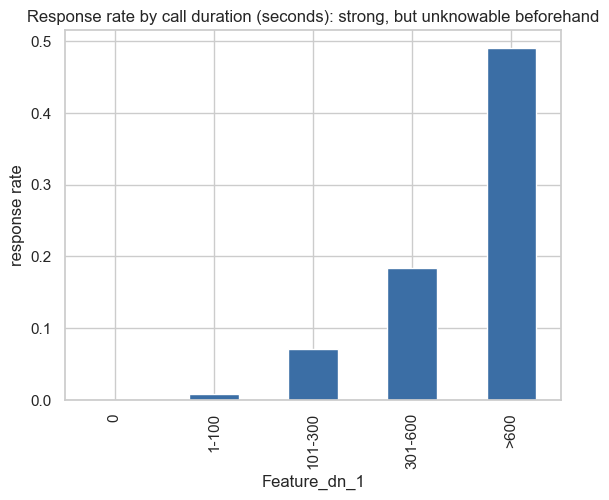

In [7]:
duration_band = pd.cut(
    raw.Feature_dn_1,
    [-1, 0, 100, 300, 600, 5000],
    labels=["0", "1-100", "101-300", "301-600", ">600"],
)
by_duration = raw.groupby(duration_band).agg(
    customers=(TARGET, "size"),
    response_rate=(TARGET, "mean"),
).round(3)
display(by_duration)

by_duration.response_rate.plot.bar(
    color=BLUE,
    title="Response rate by call duration (seconds): strong, but unknowable beforehand",
)
plt.ylabel("response rate")
plt.show()

### 1.5 Distributions & outliers

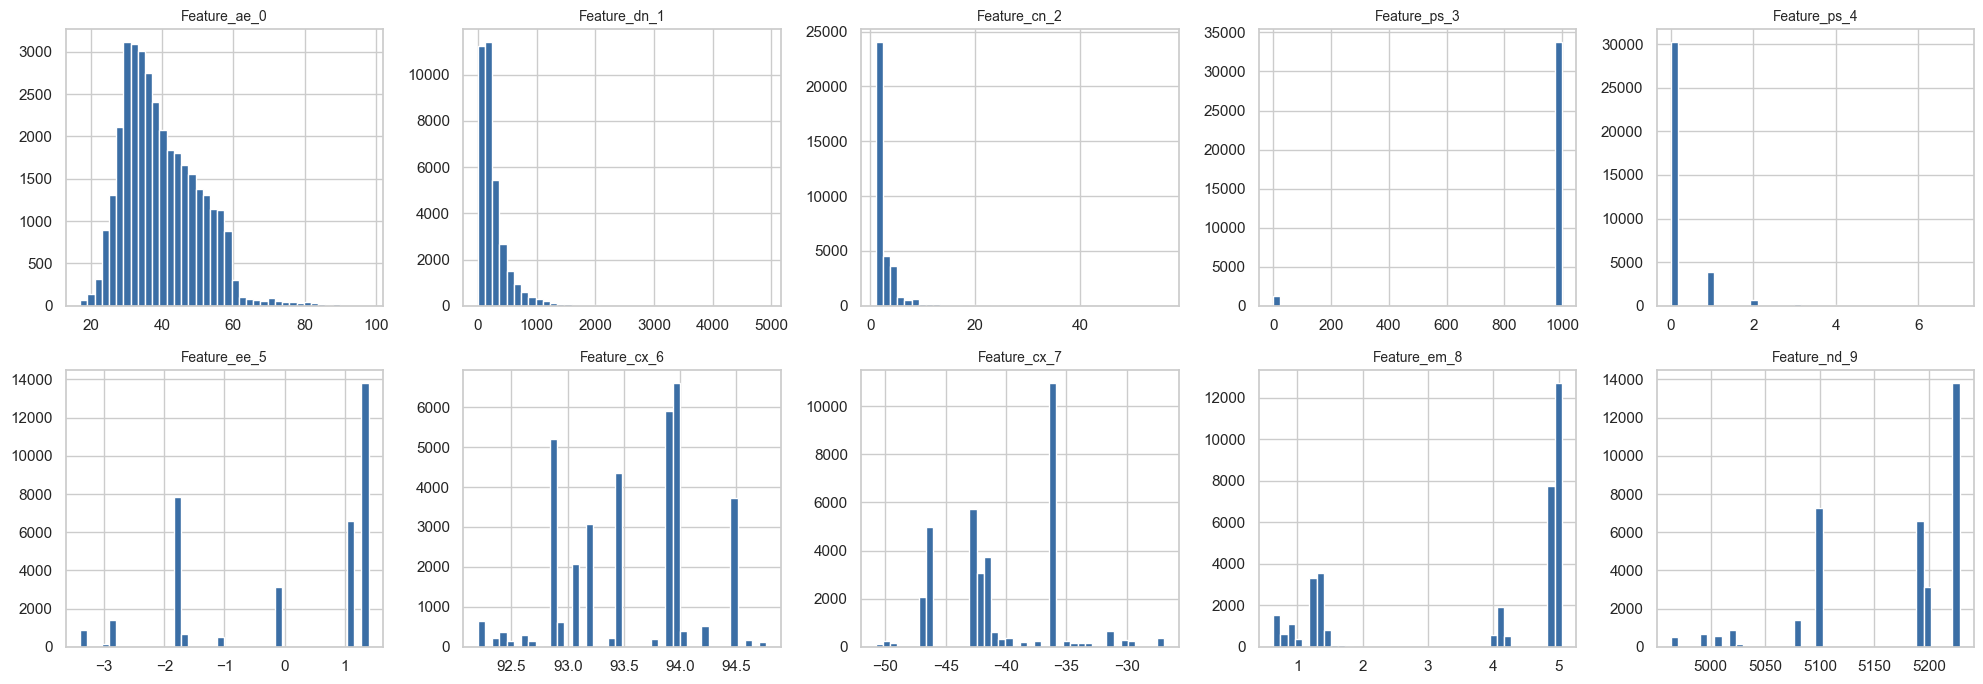

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), NUM):
    ax.hist(raw[col], bins=40, color=BLUE)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

In [9]:
rows = []
for col in ["Feature_ae_0", "Feature_dn_1", "Feature_cn_2", "Feature_ps_4"]:
    q1, q3 = raw[col].quantile([0.25, 0.75])
    fence = q3 + 1.5 * (q3 - q1)
    rows.append((col, raw[col].max(), raw[col].quantile(0.99), fence, int((raw[col] > fence).sum())))
display(pd.DataFrame(rows, columns=["var", "max", "p99", "IQR upper fence", "n above fence"]).round(1))

many_calls = raw.Feature_cn_2 > 20
print(
    "\nCustomers with >20 call attempts:", int(many_calls.sum()),
    "| their response rate:", raw.loc[many_calls, TARGET].mean(),
)

,var,max,p99,IQR upper fence,n above fence
0,Feature_ae_0,98,71.0,69.5,402
1,Feature_dn_1,4918,1268.0,642.0,2534
2,Feature_cn_2,56,14.0,6.0,2036
3,Feature_ps_4,7,2.0,0.0,4808



Customers with >20 call attempts: 134 | their response rate: 0.007462686567164179


### Stage 1: Decisions

| Finding | Decision | Why |
| --- | --- | --- |
| 11 duplicate rows | Drop | Negligible; avoids double-counting |
| No missing values; "unknown" is a category | Keep as its own level | Unknown can carry signal |
| `ps_3`: 999 code (96% of rows) | Replace with flag `prev_contacted` | The code is not a quantity |
| `dn_1`: call duration | **Exclude** | Leakage: unknown at decision time |
| `cn_2`: extreme counts (max 56) | Cap at 10 | Few rows, <1% response beyond 20 attempts, limits leverage |
| Age > 70 (~1%) | Keep | Real customers, not errors |
| Rare levels (e.g. 3 rows with default = yes, 69 with unknown civil status) | Pool in Stage 3 | Too few rows to estimate reliably |

---

# Stage 2: Feature relevance, discriminating power, correlation

### 2.1 Split first

Variable selection uses the target, so it is done on **training data only**; otherwise the test set leaks into feature choice and flatters the test score. The split is stratified 70/30 so both parts keep the 11.2% response rate.

In [10]:
df = raw.drop_duplicates().reset_index(drop=True)
train, test = train_test_split(df, test_size=0.30, stratify=df[TARGET], random_state=SEED)
print(
    f"train={len(train):,} test={len(test):,} | "
    f"response rate train={train[TARGET].mean():.4f} test={test[TARGET].mean():.4f}"
)
y = train[TARGET]

train=24,492 test=10,497 | response rate train=0.1123 test=0.1123


### 2.2 Information Value (IV) & Weight of Evidence (WoE)

For each bin: WoE = ln(%non-responders / %responders); IV = Σ (%non − %resp) × WoE. Numeric variables are binned into deciles; `ps_3` is first converted to a flag.

| IV | Reading |
| --- | --- |
| < 0.02 | useless |
| 0.02 - 0.1 | weak |
| 0.1 - 0.3 | medium |
| 0.3 - 0.5 | strong |
| > 0.5 | suspiciously strong: check for leakage |

In [11]:
def information_value(x, y):
    """Information Value of a binned or categorical variable `x` against the binary target `y`."""
    t = pd.DataFrame({"x": x, "y": y}).groupby("x").y.agg(["sum", "count"])
    t["n"] = t["count"] - t["sum"]
    t = t + 0.5  # smoothing avoids log(0)
    pct_non, pct_resp = t["n"] / t["n"].sum(), t["sum"] / t["sum"].sum()
    return float(((pct_non - pct_resp) * np.log(pct_non / pct_resp)).sum())


train_eda = train.copy()
train_eda["ps3_prev_contacted"] = (train_eda.Feature_ps_3 < 999).astype(int)

rows = []
for col in [c for c in NUM if c != "Feature_ps_3"]:
    binned = pd.qcut(train_eda[col], 10, duplicates="drop")
    rows.append((col, "numeric", information_value(binned, y), roc_auc_score(y, train_eda[col])))
for col in CAT:
    rows.append((col, "categorical", information_value(train_eda[col], y), np.nan))
rows.append((
    "ps3_prev_contacted (from Feature_ps_3)", "flag",
    information_value(train_eda.ps3_prev_contacted, y),
    roc_auc_score(y, train_eda.ps3_prev_contacted),
))

iv_table = (
    pd.DataFrame(rows, columns=["variable", "type", "IV", "univariate_AUC"])
    .sort_values("IV", ascending=False)
    .reset_index(drop=True)
)
iv_table["tier"] = pd.cut(
    iv_table.IV,
    [-1, 0.02, 0.1, 0.3, 0.5, 99],
    labels=["useless", "weak", "medium", "strong", "very strong / check leakage"],
)
display(iv_table.round(3))

,variable,type,IV,univariate_AUC,tier
0,Feature_dn_1,numeric,1.934,0.823,very strong / check leakage
1,Feature_nd_9,numeric,1.114,0.258,very strong / check leakage
2,Feature_em_8,numeric,0.991,0.264,very strong / check leakage
3,Feature_ee_5,numeric,0.746,0.291,very strong / check leakage
4,Feature_cx_7,numeric,0.740,0.534,very strong / check leakage
5,ps3_prev_contacted (from Feature_ps_3),flag,0.545,0.596,very strong / check leakage
6,Feature_pd_19,categorical,0.543,NaN,very strong / check leakage
7,Feature_md_17,categorical,0.477,NaN,strong
8,Feature_cx_6,numeric,0.469,0.397,strong
9,Feature_cd_16,categorical,0.241,NaN,medium


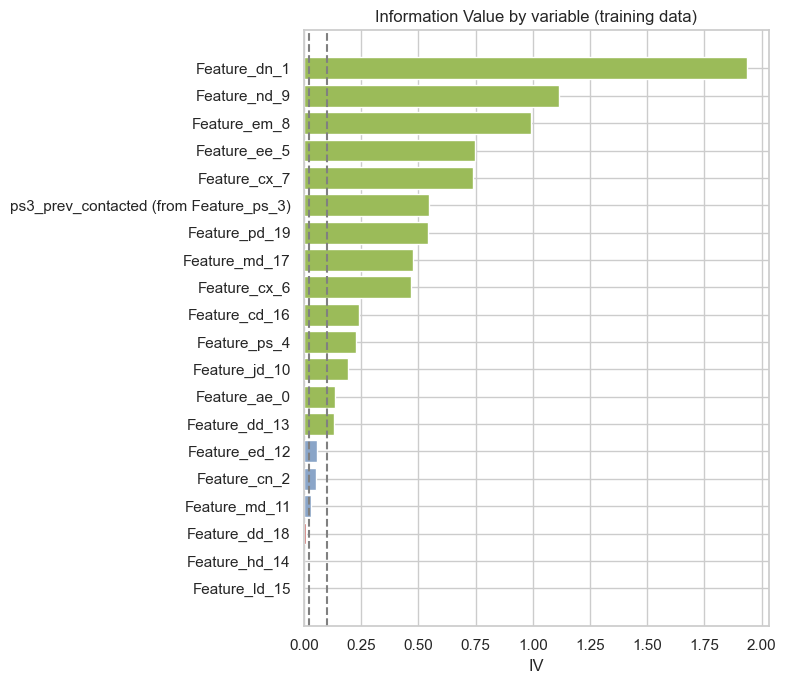

In [12]:
plot_df = iv_table.sort_values("IV")
bar_colours = plot_df.IV.map(lambda v: RED if v < 0.02 else GREEN if v >= 0.1 else LIGHT_BLUE)

plt.figure(figsize=(8, 7))
plt.barh(plot_df.variable, plot_df.IV, color=bar_colours)
plt.axvline(0.02, ls="--", c=GREY)
plt.axvline(0.1, ls="--", c=GREY)
plt.title("Information Value by variable (training data)")
plt.xlabel("IV")
plt.tight_layout()
plt.show()

**Two cautions**

1. `Feature_ps_3` scores IV ≈ 0 if binned naively (96% of values are identical) but **0.55** as a flag: how a variable is treated decides its apparent power.
2. The macro variables have very high IV but few distinct values: they mostly encode *when* the call happened (the economic cycle). Strong in-sample, but a generalisation risk if conditions change.

### 2.3 Correlation and multicollinearity

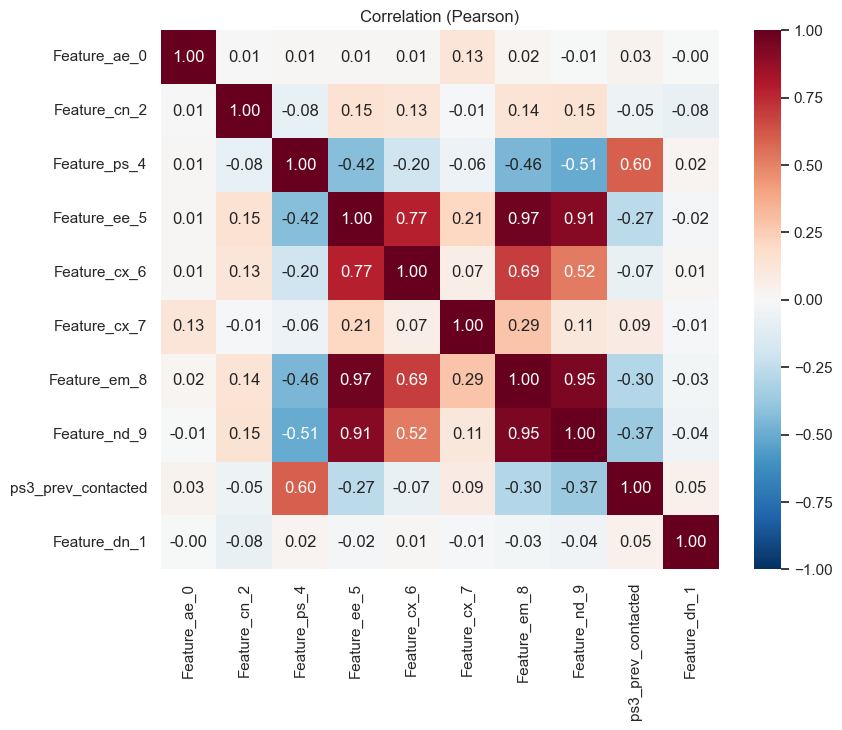

In [13]:
corr_cols = [
    "Feature_ae_0", "Feature_cn_2", "Feature_ps_4", "Feature_ee_5", "Feature_cx_6",
    "Feature_cx_7", "Feature_em_8", "Feature_nd_9", "ps3_prev_contacted",
]

plt.figure(figsize=(9, 7))
sns.heatmap(
    train_eda[corr_cols + ["Feature_dn_1"]].corr(),
    annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
)
plt.title("Correlation (Pearson)")
plt.show()

In [14]:
def vif_table(cols):
    """Variance inflation factor of each column, computed on standardised training data."""
    X = train_eda[cols].astype(float)
    X = (X - X.mean()) / X.std()
    X["const"] = 1.0
    vifs = [variance_inflation_factor(X.values, i) for i in range(len(cols))]
    return pd.Series(vifs, index=cols).round(1)


vif_all = vif_table(corr_cols)
vif_reduced = vif_table([c for c in corr_cols if c not in ("Feature_ee_5", "Feature_nd_9")])
display(pd.DataFrame({"VIF (all)": vif_all, "VIF (keep em_8 only of the 3)": vif_reduced}))

,VIF (all),VIF (keep em_8 only of the 3)
Feature_ae_0,1.0,1.0
Feature_cn_2,1.0,1.0
Feature_cx_6,6.3,2.1
Feature_cx_7,2.6,1.2
Feature_ee_5,32.7,NaN
Feature_em_8,64.0,2.8
Feature_nd_9,31.6,NaN
Feature_ps_4,1.8,1.8
ps3_prev_contacted,1.6,1.6


A VIF above 5-10 means a variable is largely predictable from the others. `ee_5`, `em_8` and `nd_9` have VIFs of ~32-64 (pairwise correlation 0.91-0.97): they are essentially one variable, which makes logistic-regression coefficients unstable and uninterpretable.

**Action:** keep exactly one of the three (chosen empirically in 3.6). The right-hand column illustrates this with `em_8`: every remaining VIF drops below 3. With `ee_5`, the variable finally chosen in 3.6, the highest VIF is 3.4, still well under the 5-10 warning level.

### 2.4 Leakage test: how much does call duration inflate the model?

Including call duration lifts test AUC from 0.80 to 0.94, confirming it must be excluded.

,Test AUC
All 20 features (incl. duration),0.935
Without call duration,0.802
Without duration & call attempts,0.801


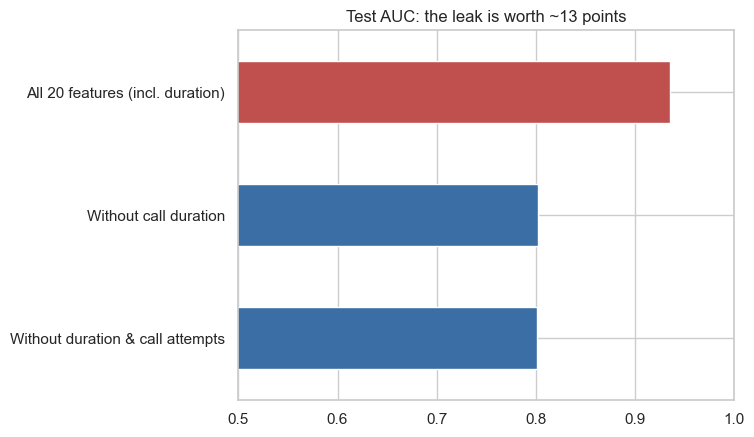

In [15]:
def quick_auc(cols):
    """Test AUC of a plain standardised logistic regression using `cols` (one-hot for categoricals)."""
    train_x = pd.get_dummies(train[cols], drop_first=True).astype(float)
    test_x = pd.get_dummies(test[cols], drop_first=True).astype(float).reindex(columns=train_x.columns, fill_value=0)
    mean, std = train_x.mean(), train_x.std().replace(0, 1)
    model = LogisticRegression(max_iter=3000).fit((train_x - mean) / std, train[TARGET])
    return roc_auc_score(test[TARGET], model.predict_proba((test_x - mean) / std)[:, 1])


features = [c for c in df.columns if c != TARGET]
leak_check = pd.Series({
    "All 20 features (incl. duration)": quick_auc(features),
    "Without call duration": quick_auc([c for c in features if c != "Feature_dn_1"]),
    "Without duration & call attempts": quick_auc([c for c in features if c not in ("Feature_dn_1", "Feature_cn_2")]),
}).round(3)
display(leak_check.to_frame("Test AUC"))

leak_check.plot.barh(color=[RED, BLUE, BLUE]).invert_yaxis()
plt.xlim(0.5, 1)
plt.title("Test AUC: the leak is worth ~13 points")
plt.show()

### 2.5 Call attempts vs response

Response falls steadily as attempts rise (13.1% at one attempt, 3.8% at ten or more). This shows a pattern, not that extra calls cause the drop: customers who keep refusing are the ones who get called again and again.

Feature_cn_2,1,2,3,4,5,6,7,8,9,10
response_rate,0.131,0.113,0.105,0.085,0.075,0.083,0.064,0.04,0.084,0.038
n,10533.000,6191.000,3235.000,1506.000,987.000,565.000,388.000,247.00,179.000,661.000


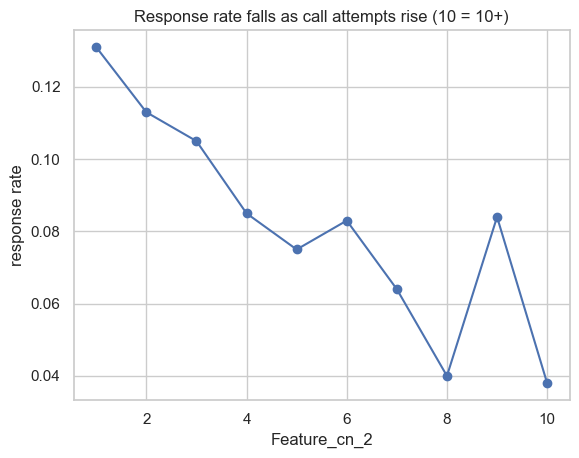

In [16]:
by_calls = (
    train_eda.groupby(train_eda.Feature_cn_2.clip(upper=10))
    .Response.agg(response_rate="mean", n="size")
    .round(3)
)
display(by_calls.T)

by_calls.response_rate.plot(marker="o", title="Response rate falls as call attempts rise (10 = 10+)")
plt.ylabel("response rate")
plt.show()

### Stage 2: Decisions

| Group | Variables | Decision |
| --- | --- | --- |
| Drop (leakage) | `Feature_dn_1` | Not available before the call |
| Drop (no signal) | `hd_14`, `ld_15` (IV ≈ 0.001), `dd_18` (0.008) | Noise; fewer variables means a simpler, more stable model |
| Collinear trio | `ee_5`, `em_8`, `nd_9` | Keep exactly one; chosen by CV in 3.6 |
| Transform | `ps_3` → `prev_contacted` flag | Handles the 999 code |
| Weak / borderline | `md_11`, `ed_12`, `cn_2` | Keep provisionally; cap `cn_2`; let validation decide |
| Keep | `pd_19`, `md_17`, `cd_16`, `jd_10`, `ps_4`, `ae_0`, `dd_13`, `cx_6`, `cx_7`, plus one of the macro trio | Medium to strong IV |

`pd_19` (previous campaign outcome, IV 0.54) is **legitimate, not leakage**: it is recorded before any new call is made. Leakage is about availability at decision time, not about how high the IV is.

---

# Stage 3: Data preparation

Every choice is made either from a principle that can be defended, or by an experiment run with **cross-validation on the training set only**. The test set stays locked until Stage 5. The macro variable left open in Stage 2 is settled in 3.6.

In [17]:
FRIENDLY = {
    "Feature_ee_5": "Employment variation rate (macro)",
    "Feature_cx_6": "Consumer price index (macro)",
    "Feature_cx_7": "Consumer confidence (macro)",
    "Feature_em_8": "3m interbank rate (macro)",
    "Feature_nd_9": "Number of employees (macro)",
    "Feature_jd_10": "Employment type",
    "Feature_md_11": "Civil status",
    "Feature_ed_12": "Education",
    "Feature_dd_13": "Credit in default",
    "Feature_hd_14": "Home loan",
    "Feature_ld_15": "Personal loan",
    "Feature_cd_16": "Contact medium",
    "Feature_md_17": "Month last contacted",
    "Feature_dd_18": "Weekday last contacted",
    "Feature_pd_19": "Previous campaign outcome",
    "age": "Age",
    "calls": "Call attempts (capped at 10)",
    "prev_calls": "Previous-campaign attempts",
    "prev_contacted": "Previously contacted (flag)",
}
MACRO_COLS = ["Feature_ee_5", "Feature_cx_6", "Feature_cx_7", "Feature_em_8", "Feature_nd_9"]


def engineer(d):
    """Build model inputs from raw columns.

    Only stateless transformations (fixed constants, nothing learned from data), so they cannot
    leak information across the train/test split. Call duration (Feature_dn_1) is deliberately
    NOT carried over (leakage).
    """
    out = pd.DataFrame(index=d.index)
    out["age"] = d.Feature_ae_0
    out["calls"] = d.Feature_cn_2.clip(upper=10)              # cap extreme attempt counts (Stage 1)
    out["prev_calls"] = d.Feature_ps_4
    out["prev_contacted"] = (d.Feature_ps_3 < 999).astype(int)  # replace the 999 code (Stage 1)
    for col in MACRO_COLS + CAT:
        out[col] = d[col]
    return out


X_tr, X_te = engineer(train), engineer(test)
y_tr, y_te = train[TARGET].values, test[TARGET].values
print(X_tr.shape, X_te.shape)

(24492, 19) (10497, 19)


### 3.1 Which columns go forward?

| Decision | Columns | Evidence |
| --- | --- | --- |
| Excluded: leakage | `Feature_dn_1` | Unknown before the call (Stage 1) |
| Excluded: no signal | `Feature_hd_14`, `Feature_ld_15`, `Feature_dd_18` | IV ≤ 0.008 (Stage 2); re-checked by CV in 3.7 |
| Excluded: raw `Feature_ps_3` | replaced by `prev_contacted` | 999 code |
| One macro variable out of three | `ee_5` / `em_8` / `nd_9` | Collinear (VIF 32-64); chosen by CV in 3.6 |
| Capped | `calls` at 10 | Beyond that: few rows and <1% response |

### 3.2 Categorical encoding & grouping rare levels

- **One-hot encoding.** The categories are nominal (job, civil status, month, ...), so integer codes would impose a fake order on a linear model. Cardinality is low (max 12 levels), so dimensionality is not a concern.
- **Levels under 1% of training rows are pooled** into an "infrequent" level: a level with 3 or 17 customers has a response rate that is pure noise. `OneHotEncoder(min_frequency=0.01)` learns this rule on train only and applies it unchanged to test and new data (`handle_unknown="infrequent_if_exist"` also stops unseen levels from crashing scoring).
- **Considered and rejected:** WoE encoding. It is compact but must be computed inside each CV fold to avoid target leakage, and it hides the levels; for ~15 columns one-hot is simpler and equally accurate.

In [18]:
DROPPED_CATS = ["Feature_hd_14", "Feature_ld_15", "Feature_dd_18"]  # no signal (Stage 2)
CAT_POOL = [c for c in CAT if c not in DROPPED_CATS]

rare_levels = []
for col in CAT_POOL:
    levels = pd.DataFrame({"x": X_tr[col], "y": y_tr}).groupby("x").y.agg(n="size", response_rate="mean")
    levels["share"] = levels.n / len(X_tr)
    for level, r in levels[levels.share < 0.01].iterrows():
        rare_levels.append((FRIENDLY[col], level, int(r.n), round(r.share * 100, 2), round(r.response_rate, 3)))

display(pd.DataFrame(rare_levels, columns=["variable", "level", "n (train)", "% of train", "response rate"]))

,variable,level,n (train),% of train,response rate
0,Employment type,Cat_11_u***n,214,0.87,0.098
1,Civil status,Cat_3_u***n,50,0.20,0.160
2,Education,Cat_4_i***e,11,0.04,0.273
3,Credit in default,Cat_2_y***s,2,0.01,0.000
4,Month last contacted,Cat_2_d***c,114,0.47,0.509


### 3.3 Do I bin the numeric variables?

Binning captures non-linearity and outliers but loses information and adds parameters. It is treated as an empirical question: look for non-linearity, then test whether binning helps out-of-sample.

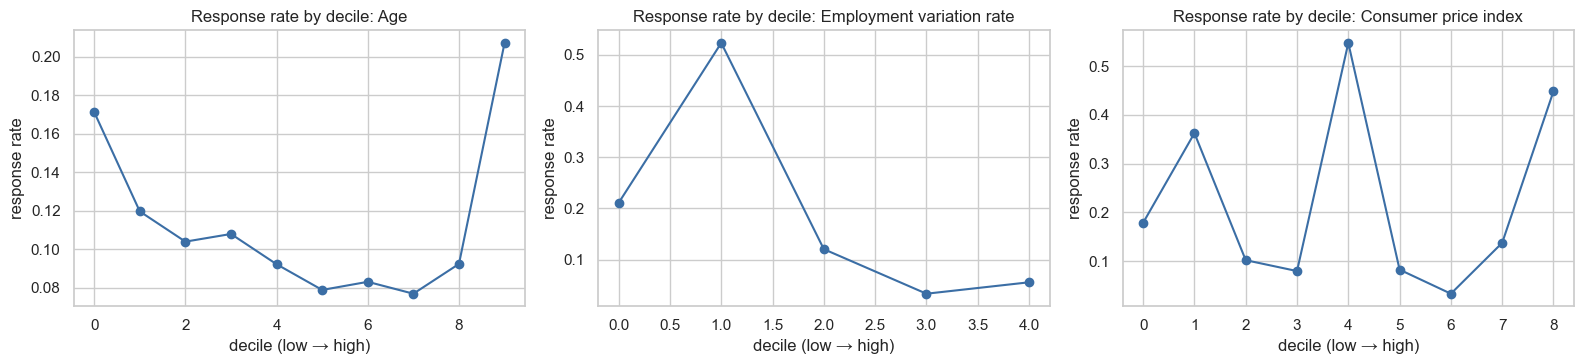

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
panels = [("age", "Age"), ("Feature_ee_5", "Employment variation rate"), ("Feature_cx_6", "Consumer price index")]
for ax, (col, label) in zip(axes, panels):
    deciles = pd.qcut(X_tr[col], 10, duplicates="drop")
    rate = pd.DataFrame({"b": deciles, "y": y_tr}).groupby("b").y.mean()
    ax.plot(range(len(rate)), rate.values, marker="o", color=BLUE)
    ax.set_title(f"Response rate by decile: {label}")
    ax.set_xlabel("decile (low → high)")
    ax.set_ylabel("response rate")
plt.tight_layout()
plt.show()

Age shows a mild U-shape (young and old respond more); the macro variables are roughly monotone. The test below shows whether binning pays for itself.

In [20]:
NUMS0 = ["age", "calls", "prev_calls", "prev_contacted", "Feature_cx_6", "Feature_cx_7", "Feature_ee_5"]  # ee_5 = macro candidate for now
CATS0 = CAT_POOL
FEATURES = NUMS0 + CATS0
BINCOLS = ["age", "calls", "prev_calls", "Feature_cx_6", "Feature_cx_7", "Feature_ee_5"]

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)  # each fold keeps ~11.2% responders


def make_pre(nums, cats, scale=True, bins=None):
    """Preprocessing: optional quantile binning, optional scaling of numerics, one-hot for categoricals."""
    parts = []
    if bins:
        parts.append(("bin", KBinsDiscretizer(n_bins=bins, encode="onehot-dense", strategy="quantile"),
                      [c for c in nums if c in BINCOLS]))
        rest = [c for c in nums if c not in BINCOLS]
    else:
        rest = nums
    parts.append(("num", StandardScaler() if scale else "passthrough", rest))
    if cats:
        parts.append(("cat", OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist", sparse_output=False), cats))
    return ColumnTransformer(parts)


def logreg(**kwargs):
    return LogisticRegression(max_iter=3000, **kwargs)


def cv_auc(model, nums=NUMS0, cats=CATS0, scale=True, bins=None):
    """Stratified-CV AUC of `model`. Preprocessing is re-fit inside every fold, so nothing leaks."""
    pipeline = Pipeline([("pre", make_pre(nums, cats, scale, bins)), ("m", model)])
    r = cross_validate(pipeline, X_tr[nums + cats], y_tr, cv=skf, scoring="roc_auc", return_train_score=True)
    return dict(cv_auc=r["test_score"].mean(), cv_sd=r["test_score"].std(), train_auc=r["train_score"].mean())


bin_results = pd.DataFrame({
    "numeric as-is (scaled)": cv_auc(logreg()),
    "numeric binned into 8 quantile bins": cv_auc(logreg(), bins=8),
}).T
display(bin_results.round(4))

,cv_auc,cv_sd,train_auc
numeric as-is (scaled),0.7835,0.0114,0.7881
numeric binned into 8 quantile bins,0.7839,0.0131,0.7904


**Decision: do not bin.** Binning adds +0.0004 AUC, far below the fold-to-fold noise (sd ≈ 0.01), for ~40 extra parameters and less interpretability. (A scorecard format would require binning/WoE regardless.)

### 3.4 Do I mind variables being on different scales?

In [21]:
scale_results = pd.DataFrame({
    "logistic, unscaled": cv_auc(logreg(), scale=False),
    "logistic, standardised": cv_auc(logreg()),
}).T
display(scale_results.round(4))

,cv_auc,cv_sd,train_auc
"logistic, unscaled",0.7827,0.0113,0.7869
"logistic, standardised",0.7835,0.0114,0.7881


**Decision: standardise for logistic regression; ignore scale for trees.**

- Logistic regression is fitted with a regularisation penalty, which acts on coefficient size. Without standardising, a variable measured in thousands (employees) and one in single digits (calls) would be penalised unequally. It also helps convergence and makes coefficients comparable.
- Trees split on thresholds, which are unaffected by monotone rescaling.
- The scaler is fit inside each CV fold, never on all data.

### 3.5 Do I care that the classes are imbalanced (11.2% / 88.8%)?

Yes, but for **how I measure** and **where I set the cut-off**, not for how I train. Options compared: do nothing, re-weight classes, resample.

In [22]:
rows = []
for name, model in [("no re-weighting", logreg()), ("class_weight='balanced'", logreg(class_weight="balanced"))]:
    pipeline = Pipeline([("pre", make_pre(NUMS0, CATS0)), ("m", model)])
    oof_pred = cross_val_predict(pipeline, X_tr[FEATURES], y_tr, cv=skf, method="predict_proba")[:, 1]
    rows.append((name, roc_auc_score(y_tr, oof_pred), average_precision_score(y_tr, oof_pred), oof_pred.mean(), y_tr.mean()))

display(pd.DataFrame(
    rows,
    columns=["approach", "AUC (out-of-fold)", "PR-AUC", "mean predicted probability", "actual response rate"],
).round(4))

,approach,AUC (out-of-fold),PR-AUC,mean predicted probability,actual response rate
0,no re-weighting,0.7829,0.4412,0.1123,0.1123
1,class_weight='balanced',0.7836,0.4358,0.3938,0.1123


**Decision: no re-weighting and no resampling.**

- Ranking quality (AUC) barely moves, but `balanced` weights wreck the **probabilities**: the model predicts ~40% average response when the truth is 11%. The profit-optimal cut-off (Stage 5) is a probability threshold, so genuine probabilities are needed.
- With ~2,750 responders in training the minority class is large enough to learn from without synthetic samples, and resampling would have to be done inside every CV fold to avoid inflated scores.
- Imbalance is handled instead through (a) stratified splits and folds, (b) suitable metrics (AUC, PR-AUC, KS, lift, profit; not accuracy), and (c) a cost-based cut-off rather than 0.5.

### 3.6 Choosing the macro variable (the collinear trio)

Three near-identical variables; exactly one is kept. Each is tested with two different learners (linear and boosted trees) so the choice is not an artefact of one model.

In [23]:
rows = []
for macro in ["Feature_ee_5", "Feature_em_8", "Feature_nd_9"]:
    nums = [c for c in NUMS0 if c != "Feature_ee_5"] + [macro]
    lr_res = cv_auc(logreg(), nums=nums)
    gb_res = cv_auc(HistGradientBoostingClassifier(random_state=SEED), nums=nums, scale=False)
    rows.append((FRIENDLY[macro], lr_res["cv_auc"], lr_res["cv_sd"], gb_res["cv_auc"], gb_res["cv_sd"]))

all_three = cv_auc(logreg(), nums=NUMS0 + ["Feature_em_8", "Feature_nd_9"])
rows.append(("all three together", all_three["cv_auc"], all_three["cv_sd"], np.nan, np.nan))

no_macro = cv_auc(logreg(), nums=[c for c in NUMS0 if c not in ("Feature_ee_5", "Feature_cx_6", "Feature_cx_7")])
rows.append(("no macro variables at all", no_macro["cv_auc"], no_macro["cv_sd"], np.nan, np.nan))

display(pd.DataFrame(rows, columns=["macro choice", "LR CV AUC", "LR sd", "HistGB CV AUC", "HistGB sd"]).round(4))

,macro choice,LR CV AUC,LR sd,HistGB CV AUC,HistGB sd
0,Employment variation rate (macro),0.7835,0.0114,0.7835,0.0105
1,3m interbank rate (macro),0.7800,0.0096,0.7895,0.0104
2,Number of employees (macro),0.7799,0.0105,0.7831,0.0122
3,all three together,0.7833,0.0122,NaN,NaN
4,no macro variables at all,0.7550,0.0083,NaN,NaN


1. The three single choices are **statistically indistinguishable** (differences ≤ 0.006 against a fold sd of ≈ 0.011), and neither model consistently prefers one.
2. Using all three together adds nothing (0.7833 vs 0.7835): they are redundant.
3. Removing *all* macro information costs ~0.03 AUC, so the macro block is the most informative group (see the generalisation caveat in Stage 7).

**Decision: `Feature_ee_5` (employment variation rate).** With the candidates tied, it is the most directly interpretable ("is employment rising or falling?") and the best of the three under logistic regression, the model finally used. This is a judgement call, not a statistical win.

### 3.7 Re-checking weak variables with CV (not just IV)

In [24]:
variants = {
    "chosen feature set": cv_auc(logreg()),
    "+ home loan, personal loan, weekday": cv_auc(logreg(), cats=CATS0 + DROPPED_CATS),
    "− call attempts": cv_auc(logreg(), nums=[c for c in NUMS0 if c != "calls"]),
    "− previous outcome (pd_19)": cv_auc(logreg(), cats=[c for c in CATS0 if c != "Feature_pd_19"]),
}
display(pd.DataFrame(variants).T.round(4))

,cv_auc,cv_sd,train_auc
chosen feature set,0.7835,0.0114,0.7881
"+ home loan, personal loan, weekday",0.7840,0.0104,0.7895
− call attempts,0.7832,0.0111,0.7877
− previous outcome (pd_19),0.7833,0.0112,0.7879


- Adding back the three IV-flagged variables changes AUC by < 0.001: **they stay dropped** (simpler, more stable, cheaper to collect).
- `calls` adds only ~0.0003 AUC and is slightly leak-prone (its count includes the current call). It is kept as a capped variable; production could drop it at no loss.
- Removing `pd_19` costs only ~0.0002 AUC because `prev_contacted` already carries most of its signal. It is kept: customers whose last campaign succeeded respond 65% of the time vs 11% overall.

### 3.8 Final feature set & split strategy

| Group | Variables |
| --- | --- |
| Numeric (7) | age, calls (capped), previous attempts, previously-contacted flag, consumer price index, consumer confidence, employment variation rate |
| Categorical (7) | employment type, civil status, education, credit default, contact medium, month last contacted, previous campaign outcome |

**Split:** 70% train / 30% test, stratified, fixed seed (done in Stage 2, before any target-aware step). All tuning uses **5-fold stratified CV within the 24,492 training rows**. The 10,497 test rows are scored **once**, in Stage 5.

---

# Stage 4: Modelling & validation

### 4.1 Approach

1. Start with a **simple, interpretable benchmark** (logistic regression); a complex model must earn its complexity.
2. Fit models of increasing flexibility (tree, random forest, gradient boosting) to see where flexibility stops paying.
3. Judge every model on **out-of-fold** predictions from 5-fold stratified CV, and check the **train vs validation gap** (a large gap signals over-fitting).

### 4.2 Criteria for the "best" model

| Criterion | Why it matters here |
| --- | --- |
| Out-of-fold **AUC** (± sd across folds) | The aim is *ranking* who is most likely to buy; AUC is threshold-free and robust to imbalance |
| **PR-AUC** and **KS** | Focus on the minority class and on class separation |
| **Train − validation gap** | Over-fitting check |
| **Calibration** (Brier score, reliability) | The profit maths in Stage 6 needs real probabilities |
| **Interpretability & stability** | A model the business and risk teams can explain and trust |
| **Simplest model within 1 standard error of the best** | Do not pay for complexity that is within noise |

In [25]:
def ks_stat(y, p):
    """Kolmogorov-Smirnov statistic: maximum gap between the true- and false-positive rates."""
    fpr, tpr, _ = roc_curve(y, p)
    return float((tpr - fpr).max())


def run_cv(model, scale, nums=NUMS0, cats=CATS0):
    """5-fold CV returning per-fold validation AUC, per-fold training AUC and out-of-fold probabilities."""
    val_aucs, train_aucs, oof_pred = [], [], np.zeros(len(y_tr))
    for train_idx, val_idx in skf.split(X_tr, y_tr):
        pipeline = Pipeline([("pre", make_pre(nums, cats, scale)), ("m", clone(model))])
        pipeline.fit(X_tr.iloc[train_idx][nums + cats], y_tr[train_idx])
        p_val = pipeline.predict_proba(X_tr.iloc[val_idx][nums + cats])[:, 1]
        p_train = pipeline.predict_proba(X_tr.iloc[train_idx][nums + cats])[:, 1]
        val_aucs.append(roc_auc_score(y_tr[val_idx], p_val))
        train_aucs.append(roc_auc_score(y_tr[train_idx], p_train))
        oof_pred[val_idx] = p_val
    return np.array(val_aucs), np.array(train_aucs), oof_pred


candidates = {  # name: (model, scale numerics?)
    "Logistic regression (L2, C=1)": (logreg(), True),
    "Decision tree (no depth limit)": (DecisionTreeClassifier(random_state=0), False),
    "Decision tree (depth 4)": (DecisionTreeClassifier(max_depth=4, random_state=0), False),
    "Random forest (300 trees, leaf≥20)": (RandomForestClassifier(300, min_samples_leaf=20, n_jobs=-1, random_state=0), False),
    "Gradient boosting (defaults)": (HistGradientBoostingClassifier(random_state=0), False),
}

rows = []
for name, (model, scale) in candidates.items():
    val_aucs, train_aucs, oof_pred = run_cv(model, scale)
    rows.append((
        name, val_aucs.mean(), val_aucs.std(), train_aucs.mean(), train_aucs.mean() - val_aucs.mean(),
        average_precision_score(y_tr, oof_pred), ks_stat(y_tr, oof_pred), brier_score_loss(y_tr, oof_pred),
    ))

model_comparison = pd.DataFrame(
    rows,
    columns=["model", "CV AUC", "CV sd", "train AUC", "gap (train−CV)", "PR-AUC", "KS", "Brier"],
).set_index("model")
display(model_comparison.round(4))

,CV AUC,CV sd,train AUC,gap (train−CV),PR-AUC,KS,Brier
model,,,,,,,
"Logistic regression (L2, C=1)",0.7835,0.0114,0.7881,0.0046,0.4412,0.4687,0.0791
Decision tree (no depth limit),0.6239,0.0166,0.9979,0.3740,0.1880,0.2396,0.1531
Decision tree (depth 4),0.7726,0.0133,0.7763,0.0037,0.4103,0.4366,0.0796
"Random forest (300 trees, leaf≥20)",0.7822,0.0134,0.8550,0.0728,0.4501,0.4788,0.0783
Gradient boosting (defaults),0.7828,0.0118,0.8293,0.0464,0.4483,0.4805,0.0782


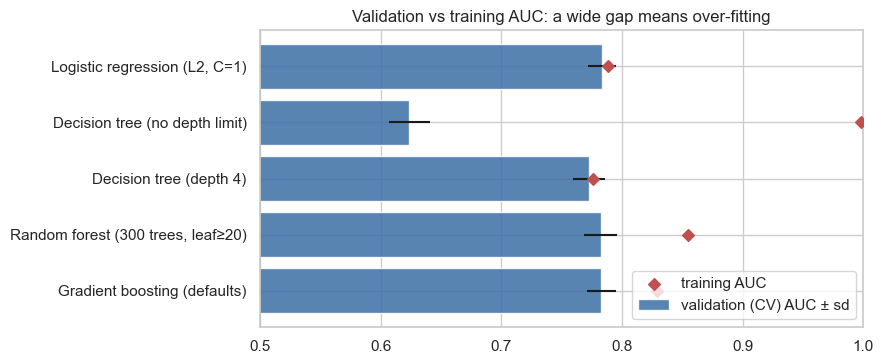

In [26]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y_pos = np.arange(len(model_comparison))
ax.barh(y_pos, model_comparison["CV AUC"], xerr=model_comparison["CV sd"], color=BLUE, alpha=0.85, label="validation (CV) AUC ± sd")
ax.scatter(model_comparison["train AUC"], y_pos, color=RED, marker="D", zorder=3, label="training AUC")
ax.set_yticks(y_pos)
ax.set_yticklabels(model_comparison.index)
ax.invert_yaxis()
ax.set_xlim(0.5, 1.0)
ax.axvline(0.5, c=GREY, lw=0.5)
ax.set_title("Validation vs training AUC: a wide gap means over-fitting")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 4.3 Reading the comparison

- **Unconstrained tree:** train AUC ≈ 1.00 vs validation ≈ 0.63. It has memorised the training rows (over-fitting), which is why validation is non-negotiable.
- **Depth-4 tree:** no train/validation gap but slightly lower AUC: mild under-fit.
- **Random forest / gradient boosting (defaults):** validation AUC ≈ 0.78, no better than logistic regression, with a train-validation gap of 5-7 points: they fit noise the logistic model leaves alone.
- **Logistic regression:** train ≈ validation (gap ≈ 0.005), stable, and a Brier score (0.079) essentially equal to the flexible models', so simplicity costs nothing in calibration.

**Headline:** all sensible models land at ≈ 0.78 AUC. The usable signal is mostly additive and close to linear, so extra flexibility has little left to find.

### 4.4 Controlling over- and under-fitting

One complexity knob (tree depth) is varied while watching training vs validation AUC.

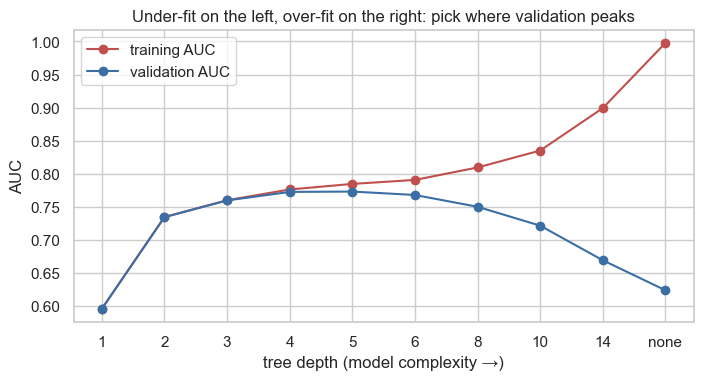

Best validation depth: 5 | validation AUC 0.7732


In [27]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 14, None]
train_curve, val_curve = [], []
for depth in depths:
    val_aucs, train_aucs, _ = run_cv(DecisionTreeClassifier(max_depth=depth, random_state=0), scale=False)
    val_curve.append(val_aucs.mean())
    train_curve.append(train_aucs.mean())

depth_labels = [str(d) if d else "none" for d in depths]
plt.figure(figsize=(8, 3.8))
plt.plot(depth_labels, train_curve, marker="o", c=RED, label="training AUC")
plt.plot(depth_labels, val_curve, marker="o", c=BLUE, label="validation AUC")
plt.xlabel("tree depth (model complexity →)")
plt.ylabel("AUC")
plt.title("Under-fit on the left, over-fit on the right: pick where validation peaks")
plt.legend()
plt.show()
print("Best validation depth:", depth_labels[int(np.argmax(val_curve))], "| validation AUC", round(max(val_curve), 4))

Validation AUC peaks at a shallow tree (depth ≈ 5) then falls while training AUC keeps rising: the over-fit zone. Hence:

- Model complexity is chosen on **validation** data, never training data. Regularisation (penalty `C`, depth, leaf size, learning rate) is tuned by CV in Stage 5.
- The 30% test set gives one unbiased read at the end; a score far below CV would signal over-fitting to the validation process.

### 4.5 Ablations: how fragile is the 0.78?

Robustness probes on the logistic model.

In [28]:
ablations = {
    "chosen model": cv_auc(logreg()),
    "drop all macro variables": cv_auc(logreg(), nums=["age", "calls", "prev_calls", "prev_contacted"]),
    "drop previous-campaign variables": cv_auc(
        logreg(),
        nums=["age", "calls", "Feature_cx_6", "Feature_cx_7", "Feature_ee_5"],
        cats=[c for c in CATS0 if c != "Feature_pd_19"],
    ),
    "customer attributes only (age, job, marital, education, default)": cv_auc(
        logreg(), nums=["age"], cats=["Feature_jd_10", "Feature_md_11", "Feature_ed_12", "Feature_dd_13"]
    ),
}
display(pd.DataFrame(ablations).T[["cv_auc", "cv_sd", "train_auc"]].round(4))

,cv_auc,cv_sd,train_auc
chosen model,0.7835,0.0114,0.7881
drop all macro variables,0.7550,0.0083,0.7600
drop previous-campaign variables,0.7781,0.0105,0.7822
"customer attributes only (age, job, marital, education, default)",0.6493,0.0116,0.6550


- **Who the customer is** (age, job, marital status, education) carries little ranking power alone (AUC ≈ 0.65).
- **When and how we contact them** (macro conditions, month, contact medium, previous campaign) carries most of it: timing and context beat demographics.
- A model leaning on the economic cycle may not transfer if conditions change (see Stage 7).

**Stage 4 conclusion:** logistic regression is a strong, honest benchmark and the flexible models show no reliable gain. Stage 5 gives them a fair chance with proper tuning before the choice is made.

---

# Stage 5: Tuning, selection, importance & cut-off

### 5.1 Which model to optimise?

Comparing a tuned model against defaults is not fair, so each finalist gets **equal tuning effort** (cross-validated search on the training set only). Then a rule agreed in advance is applied: the **one-standard-error rule** picks the simplest model whose CV AUC is within one standard error of the best. Complexity order: logistic < boosting (shallow trees) < random forest.

In [29]:
def build_pipeline(model, scale):
    """Preprocessing + model in one pipeline, so preprocessing is re-fit inside every CV fold."""
    return Pipeline([("pre", make_pre(NUMS0, CATS0, scale)), ("m", model)])


def timed_search(search):
    """Fit a hyper-parameter search on the training data; return it with its run time in seconds."""
    start = time.time()
    search.fit(X_tr[FEATURES], y_tr)
    return search, time.time() - start


searches = {}

# Logistic regression: full grid over penalty type and strength
searches["Logistic regression"] = timed_search(GridSearchCV(
    build_pipeline(LogisticRegression(solver="liblinear", max_iter=3000, random_state=SEED), scale=True),
    {"m__penalty": ["l1", "l2"], "m__C": [0.01, 0.03, 0.1, 0.3, 1]},
    cv=skf, scoring="roc_auc", return_train_score=True,
))

# Gradient boosting: random search (24 draws) with early stopping
gb_space = {
    "m__learning_rate": [0.02, 0.03, 0.05, 0.1],
    "m__max_depth": [2, 3, 4, 5, None],
    "m__max_leaf_nodes": [4, 8, 15, 31],
    "m__min_samples_leaf": [20, 50, 100, 200],
    "m__l2_regularization": [0, 1, 5, 20],
    "m__max_iter": [100, 200, 300, 500],
}
searches["Gradient boosting"] = timed_search(RandomizedSearchCV(
    build_pipeline(
        HistGradientBoostingClassifier(early_stopping=True, validation_fraction=0.15, n_iter_no_change=20, random_state=0),
        scale=False,
    ),
    gb_space, n_iter=24, cv=skf, scoring="roc_auc", random_state=0, n_jobs=-1, return_train_score=True,
))

# Random forest: random search (8 draws)
rf_space = {
    "m__min_samples_leaf": [20, 50, 100, 200],
    "m__max_depth": [4, 6, 8, 12],
    "m__max_features": ["sqrt", 0.3, 0.5],
}
searches["Random forest"] = timed_search(RandomizedSearchCV(
    build_pipeline(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=0), scale=False),
    rf_space, n_iter=8, cv=skf, scoring="roc_auc", random_state=0, return_train_score=True,
))

# Summary table
rows = []
for name, (search, seconds) in searches.items():
    i = search.best_index_
    train_auc = search.cv_results_["mean_train_score"][i]
    best_params = {k.replace("m__", ""): v for k, v in search.best_params_.items()}
    rows.append((
        name, search.best_score_, search.cv_results_["std_test_score"][i],
        train_auc, train_auc - search.best_score_, str(best_params), round(seconds),
    ))
tuned = pd.DataFrame(
    rows,
    columns=["model (tuned)", "CV AUC", "sd", "train AUC", "gap", "best hyper-parameters", "seconds"],
).set_index("model (tuned)")
display(tuned.round(4))

# One-standard-error rule (models listed from simplest to most complex)
best_mean = tuned["CV AUC"].max()
one_se = tuned.loc[tuned["CV AUC"].idxmax(), "sd"] / np.sqrt(N_FOLDS)
eligible = [m for m in ["Logistic regression", "Gradient boosting", "Random forest"] if tuned.loc[m, "CV AUC"] >= best_mean - one_se]
print(f"Best CV AUC = {best_mean:.4f}; 1 standard error = {one_se:.4f}; eligible (within 1 SE): {eligible}")
print("→ selected model (simplest eligible):", eligible[0])

lr_search = searches["Logistic regression"][0]

,CV AUC,sd,train AUC,gap,best hyper-parameters,seconds
model (tuned),,,,,,
Logistic regression,0.7847,0.0099,0.7872,0.0025,"{'C': 0.1, 'penalty': 'l1'}",21
Gradient boosting,0.7852,0.0106,0.7945,0.0093,"{'min_samples_leaf': 20, 'max_leaf_nodes': 4, ...",19
Random forest,0.7859,0.0109,0.8075,0.0216,"{'min_samples_leaf': 50, 'max_features': 0.3, ...",47


Best CV AUC = 0.7859; 1 standard error = 0.0049; eligible (within 1 SE): ['Logistic regression', 'Gradient boosting', 'Random forest']
→ selected model (simplest eligible): Logistic regression


### 5.2 Decision: regularised logistic regression

Tuning improved the flexible models a little and shrank their over-fit gap, but they do **not beat logistic regression by more than noise**: all tuned models land at ≈ 0.785 AUC (differences ~0.002 vs a standard error of ~0.005). By the pre-agreed rule, the simplest eligible model is selected. Why this is the right call:

1. **Same accuracy, less risk:** no gain in discrimination, and a much smaller over-fit gap (0.003 vs 0.009 boosting, 0.022 forest).
2. **Calibrated probabilities** natively, which the profit cut-off needs.
3. **Explainable:** every variable has a coefficient and odds ratio that Finance, Sales and Risk can read. Gradient boosting stays as the challenger confirming no hidden interaction is missed.
4. **Cheap to run, audit and monitor.**

### 5.3 How it is optimised

Two knobs: the **penalty type** (L1 shrinks weak coefficients to exactly zero, giving built-in selection; L2 shrinks smoothly) and the **strength `C`** (smaller = more regularisation = more bias, less variance). Both are searched on a grid with stratified 5-fold CV, scored by AUC (the ranking aim). Regularisation is the right lever because it directly controls the bias-variance trade-off from 4.4.

In [30]:
grid_results = pd.DataFrame(lr_search.cv_results_)[
    ["param_m__penalty", "param_m__C", "mean_test_score", "std_test_score", "mean_train_score"]
]
grid_results.columns = ["penalty", "C", "CV AUC", "sd", "train AUC"]
display(grid_results.round(4))

best_lr = lr_search.best_estimator_
print("Selected:", lr_search.best_params_, "| CV AUC =", round(lr_search.best_score_, 4))

,penalty,C,CV AUC,sd,train AUC
0,l1,0.01,0.7740,0.0091,0.7751
1,l2,0.01,0.7823,0.0088,0.7848
2,l1,0.03,0.7819,0.0090,0.7837
3,l2,0.03,0.7838,0.0101,0.7872
4,l1,0.10,0.7847,0.0099,0.7872
5,l2,0.10,0.7838,0.0108,0.7879
6,l1,0.30,0.7843,0.0105,0.7879
7,l2,0.30,0.7836,0.0112,0.7881
8,l1,1.00,0.7837,0.0111,0.7881
9,l2,1.00,0.7834,0.0113,0.7881


Selected: {'m__C': 0.1, 'm__penalty': 'l1'} | CV AUC = 0.7847


AUC is nearly flat from `C = 0.03` upward, so the model is not sensitive to the penalty. L1 with `C = 0.1` is marginally best and also drops uninformative dummy levels.

### 5.4 Over/under-fit check on the selected model

Learning curve: converging lines mean no material over-fit; training far above validation means over-fitting; both low and flat means under-fitting.

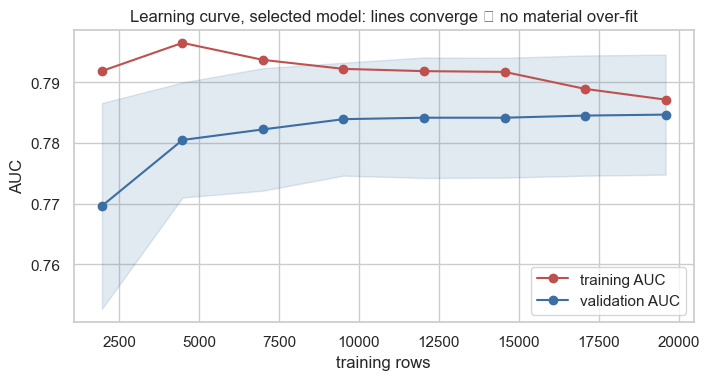

final gap (train − validation) = 0.0025


In [31]:
sizes, train_scores, val_scores = learning_curve(
    best_lr, X_tr[FEATURES], y_tr,
    train_sizes=np.linspace(0.1, 1, 8), cv=skf, scoring="roc_auc", random_state=SEED, shuffle=True,
)
plt.figure(figsize=(8, 3.8))
plt.plot(sizes, train_scores.mean(1), marker="o", c=RED, label="training AUC")
plt.plot(sizes, val_scores.mean(1), marker="o", c=BLUE, label="validation AUC")
plt.fill_between(sizes, val_scores.mean(1) - val_scores.std(1), val_scores.mean(1) + val_scores.std(1), alpha=0.15, color=BLUE)
plt.xlabel("training rows")
plt.ylabel("AUC")
plt.title("Learning curve, selected model: lines converge ⇒ no material over-fit")
plt.legend()
plt.show()
print(f"final gap (train − validation) = {train_scores.mean(1)[-1] - val_scores.mean(1)[-1]:.4f}")

Training and validation curves converge (gap ≈ 0.003): the model is **neither over- nor under-fit**, and more data would help only marginally.

### 5.5 Calibration: are the probabilities believable?

Out-of-fold predicted probability vs actual response rate, by decile. This matters because the cut-off is a probability threshold.

,customers,mean_predicted,actual_rate
decile,,,
1,2450,0.028,0.040
2,2449,0.037,0.031
3,2449,0.042,0.046
4,2449,0.051,0.047
5,2449,0.058,0.054
6,2449,0.064,0.057
7,2449,0.073,0.067
8,2450,0.099,0.094
9,2448,0.196,0.199


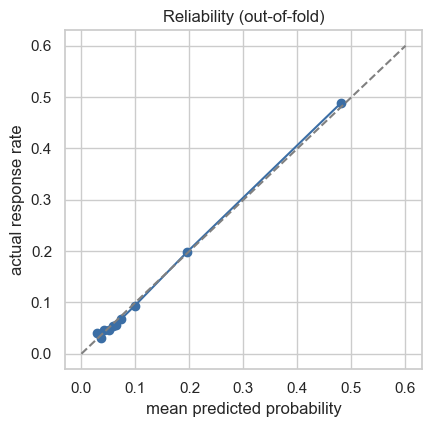

OOF AUC: 0.7841 | OOF Brier: 0.079


In [32]:
oof = cross_val_predict(best_lr, X_tr[FEATURES], y_tr, cv=skf, method="predict_proba")[:, 1]

calib = pd.DataFrame({"p": oof, "y": y_tr})
calib["decile"] = pd.qcut(calib.p, 10, labels=False, duplicates="drop") + 1
calib_table = calib.groupby("decile").agg(customers=("y", "size"), mean_predicted=("p", "mean"), actual_rate=("y", "mean"))
display(calib_table.round(3))

plt.figure(figsize=(4.6, 4.4))
plt.plot(calib_table.mean_predicted, calib_table.actual_rate, marker="o", c=BLUE)
plt.plot([0, 0.6], [0, 0.6], "--", c=GREY)
plt.xlabel("mean predicted probability")
plt.ylabel("actual response rate")
plt.title("Reliability (out-of-fold)")
plt.show()
print("OOF AUC:", round(roc_auc_score(y_tr, oof), 4), "| OOF Brier:", round(brier_score_loss(y_tr, oof), 4))

Predicted probabilities match actual rates in every decile (top decile: ~48% predicted vs ~49% actual), which is what makes a probability-based cut-off valid.

### 5.6 Choosing the cut-off

The default 0.5 is arbitrary and wrong here: with an 11% base rate almost nobody exceeds it. The right cut-off depends on what a right and a wrong call are worth. The Finance team's figures:

| Outcome of a call | Value |
| --- | --- |
| Customer **takes up** the offer | +285 (High risk, 10%) / +705 (Medium, 25%) / +1,225 (Low, 65%) → **expected +1,001** |
| Customer **does not take up** | **−300** (cost of the call) |
| We **don't call** | 0 |

Call a customer if the expected value is positive: `p × 1,001 − (1 − p) × 300 > 0`, i.e. `p > 300 / (1,001 + 300) = 0.2306`. This rule is defensible *because the probabilities are calibrated*. It is cross-checked on the out-of-fold predictions (training data only) against other popular rules.

Expected profit of a sale = 1,001.00; cost of a wasted call = -300; break-even probability t* = 0.2306


,threshold,TP,FP,FN,TN,recall,precision,profit per customer called-or-not
rule,,,,,,,,
default 0.5,0.500,588,287,2162,21455,0.214,0.672,20.516
max F1,0.235,1376,1636,1374,20106,0.500,0.457,36.199
Youden's J (max TPR−FPR),0.115,1746,3603,1004,18139,0.635,0.326,27.227
empirical profit max,0.210,1488,1994,1262,19748,0.541,0.427,36.391
break-even t* (theory),0.231,1383,1670,1367,20072,0.503,0.453,36.068


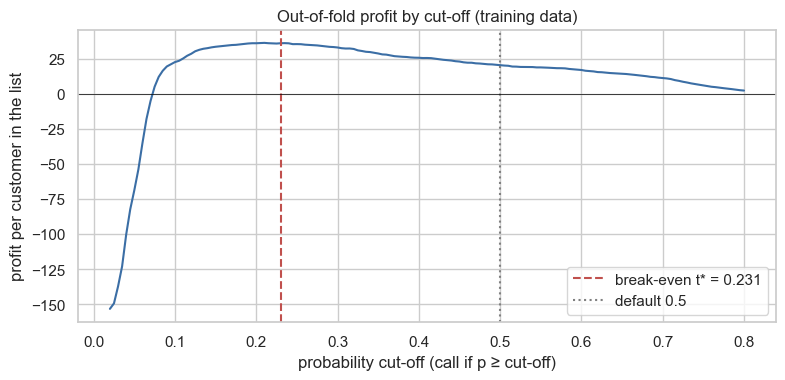

In [33]:
# Finance inputs
BANDS = {"High": (0.10, 285.0), "Medium": (0.25, 705.0), "Low": (0.65, 1225.0)}  # (share of list, net profit if taken up)
NOT_TAKEN = -300.0                                  # net profit (cost) if called and not taken up

TPV = sum(share * value for share, value in BANDS.values())  # expected profit of a sale (true-positive value)
FPC = NOT_TAKEN                                              # cost of a wasted call (false-positive cost)
t_star = -FPC / (TPV - FPC)                                  # break-even probability
print(f"Expected profit of a sale = {TPV:,.2f}; cost of a wasted call = {FPC:,.0f}; break-even probability t* = {t_star:.4f}")


def confusion_counts(y, p, threshold):
    """Return (TP, FP, FN, TN) when calling everyone whose score is >= threshold."""
    called = p >= threshold
    tp = int((called & (y == 1)).sum())
    fp = int((called & (y == 0)).sum())
    fn = int((~called & (y == 1)).sum())
    tn = int((~called & (y == 0)).sum())
    return tp, fp, fn, tn


def profit_total(y, p, threshold):
    """Total net profit of calling everyone whose score is >= threshold."""
    tp, fp, _, _ = confusion_counts(y, p, threshold)
    return tp * TPV + fp * FPC


# Profit and F1 across thresholds (out-of-fold, training data only)
thresholds = np.linspace(0.02, 0.80, 157)
profit_curve = np.array([profit_total(y_tr, oof, t) / len(y_tr) for t in thresholds])
f1_scores = []
for t in thresholds:
    tp_, fp_, fn_, _ = confusion_counts(y_tr, oof, t)
    f1_scores.append(2 * tp_ / (2 * tp_ + fp_ + fn_) if tp_ else 0)

fpr_oof, tpr_oof, roc_thresholds = roc_curve(y_tr, oof)
rules = {
    "default 0.5": 0.5,
    "max F1": thresholds[int(np.argmax(f1_scores))],
    "Youden's J (max TPR−FPR)": float(roc_thresholds[int(np.argmax(tpr_oof - fpr_oof))]),
    "empirical profit max": thresholds[int(profit_curve.argmax())],
    "break-even t* (theory)": t_star,
}

rows = []
for rule, t in rules.items():
    tp_, fp_, fn_, tn_ = confusion_counts(y_tr, oof, t)
    rows.append((rule, t, tp_, fp_, fn_, tn_, tp_ / (tp_ + fn_), tp_ / (tp_ + fp_), profit_total(y_tr, oof, t) / len(y_tr)))
cutoff_rules = pd.DataFrame(
    rows,
    columns=["rule", "threshold", "TP", "FP", "FN", "TN", "recall", "precision", "profit per customer called-or-not"],
).set_index("rule")
display(cutoff_rules.round(3))

plt.figure(figsize=(9, 3.8))
plt.plot(thresholds, profit_curve, c=BLUE)
plt.axvline(t_star, c=RED, ls="--", label=f"break-even t* = {t_star:.3f}")
plt.axvline(0.5, c=GREY, ls=":", label="default 0.5")
plt.axhline(0, c="black", lw=0.5)
plt.xlabel("probability cut-off (call if p ≥ cut-off)")
plt.ylabel("profit per customer in the list")
plt.title("Out-of-fold profit by cut-off (training data)")
plt.legend()
plt.show()

**Decision: cut-off = 0.2306 (the break-even probability).**

- It is **derived from the economics**, not tuned to the data. The empirical profit optimum (≈ 0.21) is within noise of it: the profit curve is flat around the optimum (0.21 vs 0.23 differ by ~1%).
- It beats the standard rules by a wide margin: the default 0.5 forgoes ~40% of profit because it misses most buyers.
- A call costs 300 and a sale returns 1,001 on average, so a call pays for itself if at least ~23% of similar calls convert: roughly 3 failed calls per sale can be tolerated.
- It was fixed on training data only, so the test set remains an honest judge.

### 5.7 Final fit & one-time test-set evaluation

The model is frozen, fitted on the full training set, and the test set is scored **once**.

,value
Test AUC,0.8017
Gini (2·AUC−1),0.6035
KS,0.5036
PR-AUC,0.4521
"CV AUC (training, for comparison)",0.7847


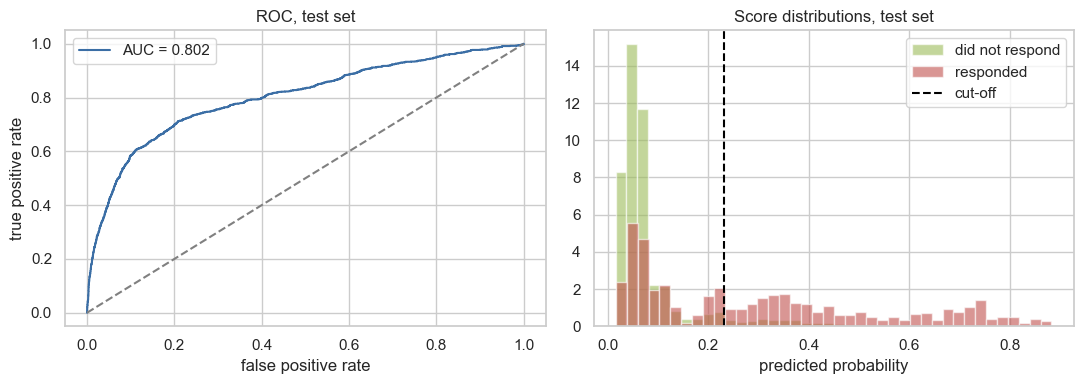

In [34]:
final = clone(best_lr).fit(X_tr[FEATURES], y_tr)
p_te = final.predict_proba(X_te[FEATURES])[:, 1]

fpr, tpr, _ = roc_curve(y_te, p_te)
auc_te = roc_auc_score(y_te, p_te)
test_summary = pd.Series({
    "Test AUC": auc_te,
    "Gini (2·AUC−1)": 2 * auc_te - 1,
    "KS": float((tpr - fpr).max()),
    "PR-AUC": average_precision_score(y_te, p_te),
    "CV AUC (training, for comparison)": lr_search.best_score_,
}).round(4)
display(test_summary.to_frame("value"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fpr, tpr, c=BLUE, label=f"AUC = {auc_te:.3f}")
axes[0].plot([0, 1], [0, 1], "--", c=GREY)
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC, test set")
axes[0].legend()

axes[1].hist(p_te[y_te == 0], bins=40, alpha=0.6, label="did not respond", color=GREEN, density=True)
axes[1].hist(p_te[y_te == 1], bins=40, alpha=0.6, label="responded", color=RED, density=True)
axes[1].axvline(t_star, c="black", ls="--", label="cut-off")
axes[1].set_xlabel("predicted probability")
axes[1].set_title("Score distributions, test set")
axes[1].legend()
plt.tight_layout()
plt.show()

Test AUC (≈ 0.80) is in line with cross-validation (≈ 0.785); the ~0.015 difference is within the sampling noise of a 10k-row test set and points the right way, so there is no sign of over-fitting to the validation process.

### 5.8 The confusion matrix at the chosen cut-off

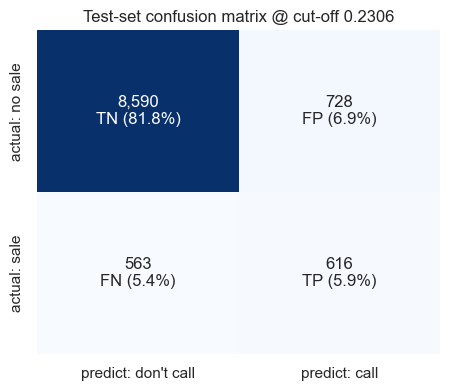

,value
Recall / sensitivity TP/(TP+FN),0.522
Precision TP/(TP+FP),0.458
Specificity TN/(TN+FP),0.922
Accuracy,0.877
Base response rate,0.112
Lift of called group vs base,4.081
Share of list we would call,0.128


In [35]:
tp, fp, fn, tn = confusion_counts(y_te, p_te, t_star)
N_te = len(y_te)

cell_labels = [
    [f"{tn:,}\nTN ({tn / N_te:.1%})", f"{fp:,}\nFP ({fp / N_te:.1%})"],
    [f"{fn:,}\nFN ({fn / N_te:.1%})", f"{tp:,}\nTP ({tp / N_te:.1%})"],
]
fig, ax = plt.subplots(figsize=(5.2, 4.2))
sns.heatmap(
    np.array([[tn, fp], [fn, tp]]), annot=cell_labels, fmt="", cmap="Blues", cbar=False,
    xticklabels=["predict: don't call", "predict: call"],
    yticklabels=["actual: no sale", "actual: sale"], ax=ax,
)
ax.set_title(f"Test-set confusion matrix @ cut-off {t_star:.4f}")
plt.show()

metrics = pd.Series({
    "Recall / sensitivity  TP/(TP+FN)": tp / (tp + fn),
    "Precision  TP/(TP+FP)": tp / (tp + fp),
    "Specificity  TN/(TN+FP)": tn / (tn + fp),
    "Accuracy": (tp + tn) / N_te,
    "Base response rate": y_te.mean(),
    "Lift of called group vs base": (tp / (tp + fp)) / y_te.mean(),
    "Share of list we would call": (tp + fp) / N_te,
})
display(metrics.round(3).to_frame("value"))

**Reading the matrix**

- **TP (≈ 5.9% of customers):** called and they buy; these pay for the campaign.
- **FP (≈ 6.9%):** called and they say no; each costs 300, the price of being aggressive.
- **FN (≈ 5.4%):** real buyers we do *not* call: pure **lost opportunity** (~1,001 expected profit each).
- **TN (≈ 81.8%):** correctly left alone.
- **Recall ≈ 52%, precision ≈ 46%:** we find about half of all buyers while calling only ≈ 13% of the list; 46% of those called buy vs 11% at random, a **lift of ≈ 4×**.
- **Accuracy (87.7%) is *lower* than "never call" (88.8%)**, which is expected: accuracy treats a missed 1,001 sale and a wasted 300 call as equal errors. This is why the cut-off is chosen on profit, not accuracy.

The gains table shows how many buyers are captured by calling the top x% of the score list.

In [36]:
gains = pd.DataFrame({"p": p_te, "y": y_te}).sort_values("p", ascending=False).reset_index(drop=True)
gains["decile"] = (gains.index * 10 // len(gains)) + 1

gains_table = gains.groupby("decile").agg(
    customers=("y", "size"), responders=("y", "sum"), response_rate=("y", "mean"), min_score=("p", "min"),
)
gains_table["cum % of all responders captured"] = gains_table.responders.cumsum() / gains_table.responders.sum()
gains_table["lift"] = gains_table.response_rate / y_te.mean()
display(gains_table.round(3))

,customers,responders,response_rate,min_score,cum % of all responders captured,lift
decile,,,,,,
1,1050,522,0.497,0.306,0.443,4.426
2,1050,229,0.218,0.123,0.637,1.942
3,1050,115,0.110,0.079,0.735,0.975
4,1049,53,0.051,0.067,0.779,0.450
5,1050,51,0.049,0.061,0.823,0.432
6,1050,48,0.046,0.055,0.863,0.407
7,1049,60,0.057,0.045,0.914,0.509
8,1050,34,0.032,0.039,0.943,0.288
9,1050,40,0.038,0.033,0.977,0.339


Calling the top 10% of scores reaches ~44% of all buyers (lift ≈ 4.4), the top 20% ~64%, the top 30% ~74%. Beyond the third decile, response is at or below the 11% average, so those calls rarely pay for themselves.

### 5.9 Which inputs matter most (and least)?

- **Permutation importance:** shuffle one variable on held-out data and measure the AUC drop. It is model-agnostic and each *original* variable is shuffled as a whole (a 12-level category is not split into 12 pieces).
- **Logistic coefficients (odds ratios):** direction and size of each effect; numeric inputs are standardised so they are comparable.

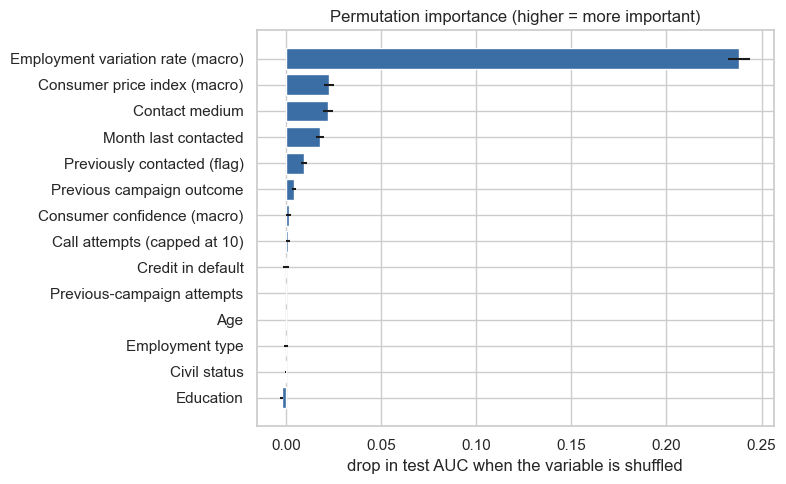

,variable,AUC drop when shuffled,sd
0,Employment variation rate (macro),0.2381,0.0060
1,Consumer price index (macro),0.0228,0.0028
2,Contact medium,0.0221,0.0027
3,Month last contacted,0.0179,0.0022
4,Previously contacted (flag),0.0095,0.0015
5,Previous campaign outcome,0.0045,0.0010
6,Consumer confidence (macro),0.0015,0.0014
7,Call attempts (capped at 10),0.0012,0.0009
8,Credit in default,0.0001,0.0014
9,Previous-campaign attempts,0.0001,0.0001


In [37]:
perm = permutation_importance(final, X_te[FEATURES], y_te, scoring="roc_auc", n_repeats=15, random_state=SEED)
importance = pd.DataFrame({
    "variable": [FRIENDLY.get(c, c) for c in FEATURES],
    "AUC drop when shuffled": perm.importances_mean,
    "sd": perm.importances_std,
}).sort_values("AUC drop when shuffled")

plt.figure(figsize=(8, 5))
plt.barh(importance.variable, importance["AUC drop when shuffled"], xerr=importance.sd, color=BLUE)
plt.xlabel("drop in test AUC when the variable is shuffled")
plt.title("Permutation importance (higher = more important)")
plt.tight_layout()
plt.show()
display(importance.sort_values("AUC drop when shuffled", ascending=False).round(4).reset_index(drop=True))

In [38]:
terms = final.named_steps["pre"].get_feature_names_out()
coefs = final.named_steps["m"].coef_[0]

coef_table = pd.DataFrame({"term": terms, "coefficient": coefs, "odds ratio": np.exp(coefs)})
coef_table["term"] = coef_table.term.str.replace("num__", "").str.replace("cat__", "")

top_terms = coef_table.reindex(coef_table.coefficient.abs().sort_values(ascending=False).index).head(12)
display(top_terms.round(3).reset_index(drop=True))
print("Coefficients shrunk to exactly zero by the L1 penalty:", int((np.abs(coefs) < 1e-9).sum()), "of", len(coefs))

,term,coefficient,odds ratio
0,Feature_ee_5,-1.102,0.332
1,Feature_md_17_Cat_5_m***r,1.049,2.854
2,Feature_cx_6,0.609,1.839
3,Feature_cd_16_Cat_1_t***e,-0.586,0.557
4,Feature_md_17_Cat_6_m***y,-0.541,0.582
5,Feature_pd_19_Cat_0_f***e,-0.447,0.639
6,Feature_md_17_Cat_7_n***v,-0.424,0.654
7,Feature_jd_10_Cat_5_r***d,0.311,1.365
8,Feature_dd_13_Cat_1_u***n,-0.265,0.767
9,prev_contacted,0.257,1.293


Coefficients shrunk to exactly zero by the L1 penalty: 22 of 49


**Findings**

- **Most important by a wide margin: employment variation rate (macro).** Shuffling it costs ~0.24 AUC, an order of magnitude more than anything else. A one-standard-deviation rise cuts the odds of a sale to about a third (OR ≈ 0.33): customers respond far more when employment is *falling*.
- **Next tier:** consumer price index, **contact medium**, **month last contacted** and whether the customer was **previously contacted**. Among levels (labels are masked), `Feature_md_17 = Cat_5_m***r` has ≈ 2.9× the odds of a sale and contact medium `Cat_1_t***e` ≈ 0.56×.
- **Effectively irrelevant:** age, employment type, civil status, education, credit default, call attempts, previous-attempt count. Some show tiny *negative* values (shuffling helps by chance), i.e. noise; they could be removed with no loss.
- The L1 penalty set 22 of the 49 model terms to exactly zero, so it also performed variable selection.
- Importance is shared between related variables (the macro block overlaps with month), so treat the ranking as indicative, not exact. Shuffling also overstates what would be lost without a variable: refitting without the whole macro block costs about 0.04 AUC, not 0.24, because month and other columns partly compensate (see 5.10).

### 5.10 Calendar-risk test: is the model just reading the calendar?

Section 5.9 showed that the model leans heavily on the employment variation rate, and the macro variables mostly encode *when* a call happened. That is the main generalisation risk (see Stage 7), so it is tested directly rather than only flagged. Both checks are diagnostic: nothing below is used to choose the model, the features or the cut-off.

- **Ablation:** refit the same model without the macro variables, and without month, which also behaves like a calendar.
- **Unseen periods:** hold out whole macro-value combinations (373 of them), so every validation row comes from economic conditions the model never saw in training.

In [39]:
from sklearn.model_selection import GroupKFold

# Calendar-risk test. Question: does the model only know *when* a call happened (through the macro
# variables), or can it also rank customers? Both checks below are diagnostic only: nothing here is
# used to choose the model, the features or the cut-off.
#   1. Ablation: refit without the macro variables, and without month (the other calendar-like column).
#   2. Unseen periods: hold out whole macro-value combinations, so every validation row comes from
#      economic conditions the model never saw while training.
X_all, y_all = engineer(df), df[TARGET].values
period = df[MACRO_COLS].astype(str).agg("|".join, axis=1)  # one label per macro-value combination
print("distinct macro combinations (our stand-in for 'periods'):", period.nunique())

# The file has no date column. Check whether the row order could stand in for time instead:
file_fifth = pd.qcut(np.arange(len(df)), 5, labels=False)
print("response rate by fifth of the file:", df.groupby(file_fifth)[TARGET].mean().round(3).tolist())

macro_in_model = ["Feature_cx_6", "Feature_cx_7", "Feature_ee_5"]
no_macro = [c for c in NUMS0 if c not in macro_in_model]
variants = {
    "full model (as chosen)": (NUMS0, CATS0),
    "no macro variables": (no_macro, CATS0),
    "no macro, no month": (no_macro, [c for c in CATS0 if c != "Feature_md_17"]),
}


def make_variant(nums, cats):
    """Same preprocessing and the same tuned logistic regression as the final model, on a subset of inputs."""
    return Pipeline([("pre", make_pre(nums, cats)), ("m", clone(best_lr.named_steps["m"]))])


def pooled_auc(nums, cats, X, y, cv, groups=None):
    """AUC of out-of-fold predictions pooled over all folds."""
    p = cross_val_predict(make_variant(nums, cats), X[nums + cats], y, cv=cv, groups=groups, method="predict_proba")[:, 1]
    return roc_auc_score(y, p)


rows = []
for name, (nums, cats) in variants.items():
    p_test = make_variant(nums, cats).fit(X_tr[nums + cats], y_tr).predict_proba(X_te[nums + cats])[:, 1]
    rows.append((
        name,
        pooled_auc(nums, cats, X_tr, y_tr, skf),                                           # random folds, training data
        pooled_auc(nums, cats, X_all, y_all, GroupKFold(n_splits=N_FOLDS), groups=period),  # whole periods held out
        roc_auc_score(y_te, p_test),
        (p_test >= t_star).mean(),
        profit_total(y_te, p_test, t_star) / N_te * 10_000,   # per 10,000 customers (as Stage 6)
    ))

calendar_test = pd.DataFrame(rows, columns=[
    "variant", "AUC: random CV", "AUC: unseen periods", "AUC: test set", "share of list called", "profit per 10,000",
]).set_index("variant")
shown = calendar_test.round(3)
shown["profit per 10,000"] = calendar_test["profit per 10,000"].round().astype(int)
display(shown)

distinct macro combinations (our stand-in for 'periods'): 373
response rate by fifth of the file: [0.114, 0.112, 0.111, 0.115, 0.11]


,AUC: random CV,AUC: unseen periods,AUC: test set,share of list called,"profit per 10,000"
variant,,,,,
full model (as chosen),0.784,0.790,0.802,0.128,379362
no macro variables,0.755,0.753,0.761,0.081,293352
"no macro, no month",0.727,0.727,0.734,0.064,207700


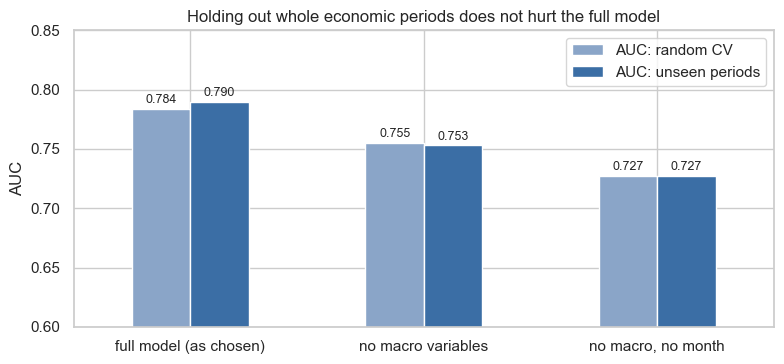

In [40]:
ax = calendar_test[["AUC: random CV", "AUC: unseen periods"]].plot.bar(color=[LIGHT_BLUE, BLUE], figsize=(8, 3.8), rot=0)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", fontsize=9, padding=2)
ax.set_ylim(0.6, 0.85)
ax.set_xlabel("")
ax.set_ylabel("AUC")
ax.set_title("Holding out whole economic periods does not hurt the full model")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Findings**

- **The model does not collapse on periods it has not seen.** With whole macro periods held out, the full model scores AUC 0.789, against 0.784 on ordinary random folds (both are pooled out-of-fold AUCs, so they sit about 0.001 below the fold-average 0.7847 in 5.1). It is not simply memorising which period each row belongs to.
- **Customer and contact features carry real signal on their own.** Without the macro variables the test AUC is 0.761 (against 0.802) and the same cut-off yields about 293,000 per 10,000 customers (against 379,000). The macro block is worth about 0.04 AUC and about 86,000, roughly 30% more profit, but it is not the whole model.
- **Month is calendar-like too.** Dropping it as well costs a further ~0.03 AUC (test 0.734, profit about 208,000).
- **This reconciles with 5.9.** Shuffling the employment variation rate cost ~0.24 AUC because that measures how much the *fitted* model leans on it. When the model is refitted without it, other columns, mainly month, recover most of that, so the real cost of losing the macro block is the ~0.04 above (the ~0.03 in 3.6 is the same effect measured by cross-validation).

**What this cannot show.** The file has no date column, and the row order is not time (response rate is flat at about 11% across every fifth of the file), so a true time-based hold-out is not possible. Holding out macro combinations tests conditions the model has not seen *within the range in the data*; it cannot show what happens if the economy moves outside that range. The recommendation stands: pilot on a small slice first, monitor the score distribution after launch, and retrain if it drifts. The no-macro model is a ready fallback at roughly three quarters of the profit, evaluated here at the unchanged 0.2306 cut-off.

---

# Stage 6 (Bonus): Campaign profit & the cost of misclassification

**The ask:** the sales team has a **10,000-record** prospect list. Assuming the confusion-matrix **percentages** match the development sample and 100% of called customers qualify for credit, compute **(a)** the expected net profit on the customers we phone and **(b)** the net profit lost through misclassification.

### 6.1 Assumptions

1. Confusion-matrix rates come from the **held-out test set** at the chosen cut-off (0.2306), to avoid flattering the model. Out-of-fold training rates are shown as a cross-check.
2. We call everyone the model flags (TP + FP) and do not call predicted 0 (TN + FN).
3. Risk bands (High 10% / Medium 25% / Low 65%) are independent of the model's prediction, so they split every group in those proportions.
4. Profit if called and sale: 285 / 705 / 1,225 by band. If called and no sale: −300 in every band. Not called: 0.
5. 100% approval: every sale converts to its stated profit.

### 6.2 Mapping the confusion matrix to money

| Cell | Meaning | Called? | Money |
| --- | --- | --- | --- |
| **TP** | would buy, we call | yes | + band profit (expected 1,001) |
| **FP** | would not buy, we call | yes | −300 |
| **FN** | would buy, we don't call | no | 0 earned: **1,001 forgone** (lost opportunity) |
| **TN** | would not buy, we don't call | no | 0 (a −300 call avoided) |

In [41]:
LIST_SIZE = 10_000
cm_pct = {"TP": tp / N_te, "FP": fp / N_te, "FN": fn / N_te, "TN": tn / N_te}  # held-out confusion-matrix shares
cnt = {k: v * LIST_SIZE for k, v in cm_pct.items()}                              # customers on the 10,000 list

# Cross-check: the same shares from out-of-fold training predictions
tp_o, fp_o, fn_o, tn_o = confusion_counts(y_tr, oof, t_star)
N_o = len(y_tr)

print("Confusion matrix on the 10,000 list (test-set rates):")
display(pd.DataFrame({
    "% of customers (test)": cm_pct,
    "customers on list": cnt,
    "(cross-check) % out-of-fold train": {"TP": tp_o / N_o, "FP": fp_o / N_o, "FN": fn_o / N_o, "TN": tn_o / N_o},
}).round(4))

# Profit by risk band
rows = []
for band, (share, value) in BANDS.items():
    n_tp, n_fp, n_fn = (cnt[k] * share for k in ("TP", "FP", "FN"))
    rows.append((
        band, share,
        n_tp, n_tp * value,                              # sales and profit from them
        n_fp, n_fp * NOT_TAKEN,                          # wasted calls and their cost
        n_tp * value + n_fp * NOT_TAKEN,                 # (a) net profit
        n_fn, n_fn * value,                              # missed buyers and forgone profit (b)
    ))
band_table = pd.DataFrame(rows, columns=[
    "risk band", "share", "TP (sales)", "profit from sales", "FP (wasted calls)", "cost of wasted calls",
    "net profit (a)", "FN (missed buyers)", "lost opportunity (b)",
]).set_index("risk band")
band_table.loc["Total"] = band_table.sum()
band_table["share"] = ["10%", "25%", "65%", "100%"]  # shown as text so 25% / 65% are not rounded

pd.options.display.float_format = "{:,.1f}".format
display(band_table)
pd.options.display.float_format = None

Confusion matrix on the 10,000 list (test-set rates):


,% of customers (test),customers on list,(cross-check) % out-of-fold train
TP,0.0587,586.8343,0.0565
FP,0.0694,693.5315,0.0682
FN,0.0536,536.3437,0.0558
TN,0.8183,8183.2905,0.8195


,share,TP (sales),profit from sales,FP (wasted calls),cost of wasted calls,net profit (a),FN (missed buyers),lost opportunity (b)
risk band,,,,,,,,
High,10%,58.7,"16,724.8",69.4,"-20,805.9","-4,081.2",53.6,"15,285.8"
Medium,25%,146.7,"103,429.6",173.4,"-52,014.9","51,414.7",134.1,"94,530.6"
Low,65%,381.4,"467,266.8",450.8,"-135,238.6","332,028.2",348.6,"427,063.7"
Total,100%,586.8,"587,421.2",693.5,"-208,059.4","379,361.7",536.3,"536,880.1"


In [42]:
net_profit = band_table.loc["Total", "net profit (a)"]
lost_fn = band_table.loc["Total", "lost opportunity (b)"]        # forgone profit on buyers we did not call
wasted = -band_table.loc["Total", "cost of wasted calls"]        # spend on calls that did not convert
perfect = (cnt["TP"] + cnt["FN"]) * TPV                          # perfect model: calls exactly the buyers
call_all = (cnt["TP"] + cnt["FN"]) * TPV + (cnt["FP"] + cnt["TN"]) * FPC

print(f"(a) Expected net profit from the campaign ............ {net_profit:>12,.0f}")
print(f"(b) Lost opportunity: buyers we did not call (FN) .... {lost_fn:>12,.0f}")
print(f"    + cost of wasted calls (FP) ...................... {wasted:>12,.0f}")
print(f"    = total profit lost to misclassification ......... {lost_fn + wasted:>12,.0f}")
print(
    f"Check: perfect-model profit {perfect:,.0f} − misclassification {lost_fn + wasted:,.0f} "
    f"= {perfect - lost_fn - wasted:,.0f}  (equals (a): {abs(perfect - lost_fn - wasted - net_profit) < 1e-6})"
)
print(f"\nBenchmarks: call nobody = 0 | call everyone = {call_all:,.0f} | model = {net_profit:,.0f} | perfect model = {perfect:,.0f}")
print(f"Model captures {net_profit / perfect:.0%} of the achievable profit.")

(a) Expected net profit from the campaign ............      379,362
(b) Lost opportunity: buyers we did not call (FN) ....      536,880
    + cost of wasted calls (FP) ......................      208,059
    = total profit lost to misclassification .........      744,940
Check: perfect-model profit 1,124,301 − misclassification 744,940 = 379,362  (equals (a): True)

Benchmarks: call nobody = 0 | call everyone = -1,538,745 | model = 379,362 | perfect model = 1,124,301
Model captures 34% of the achievable profit.


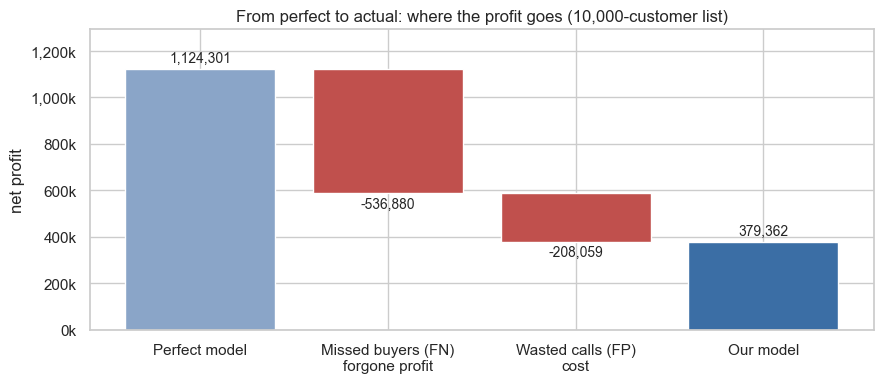

In [43]:
steps = [  # (label, bar height, bar bottom, colour)
    ("Perfect model", perfect, 0, LIGHT_BLUE),
    ("Missed buyers (FN)\nforgone profit", -lost_fn, perfect, RED),
    ("Wasted calls (FP)\ncost", -wasted, perfect - lost_fn, RED),
    ("Our model", net_profit, 0, BLUE),
]
fig, ax = plt.subplots(figsize=(9, 4))
for i, (label, height, bottom, colour) in enumerate(steps):
    ax.bar(i, height, bottom=bottom, color=colour)
    offset = 15000 if height > 0 else -15000
    ax.text(i, bottom + height + offset, f"{height:,.0f}", ha="center", va="bottom" if height > 0 else "top", fontsize=10)

ax.set_ylim(0, perfect * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}k"))
ax.set_xticks(range(len(steps)))
ax.set_xticklabels([s[0] for s in steps])
ax.set_ylabel("net profit")
ax.set_title("From perfect to actual: where the profit goes (10,000-customer list)")
ax.axhline(0, c="black", lw=0.6)
plt.tight_layout()
plt.show()

### 6.3 Answers

- **(a) Expected net profit ≈ 380,000:** about 587 sales × 1,001 average profit (≈ 587,000) less about 693 wasted calls × 300 (≈ 208,000).
- **(b) Lost opportunity from misclassification ≈ 745,000**, made up of **≈ 537,000 of profit forgone** on ≈ 536 buyers the model did not flag (false negatives) **plus ≈ 208,000 spent** on ≈ 693 calls that did not convert (false positives).

**Context:** calling *everyone* on the list would **lose ≈ 1.5 million**, because most calls fail and cost 300 each; a perfect model would earn ≈ 1.12 million. The model turns a heavy loss into a profit and captures roughly a third of the achievable profit. The biggest piece of the gap is **missed buyers**, not wasted calls.

> *Interpretation note:* "lost opportunity due to misclassifying" can be read as FN only (forgone profit) or FN + FP (all money lost to wrong calls). Both are shown so the reader can take the one that matches the client's definition.

### 6.4 How certain is this?

The estimate rests on a test set of ~10,500 customers, so the confusion-matrix rates carry sampling error. A bootstrap quantifies it, and the chart shows how the answer moves with the cut-off (diagnostic only: the cut-off is *not* re-tuned on the test set).

Expected net profit per 10,000 customers: 379,362  (95% bootstrap interval 330,646 to 428,235)
Probability the campaign is profitable under this model: 100.0%


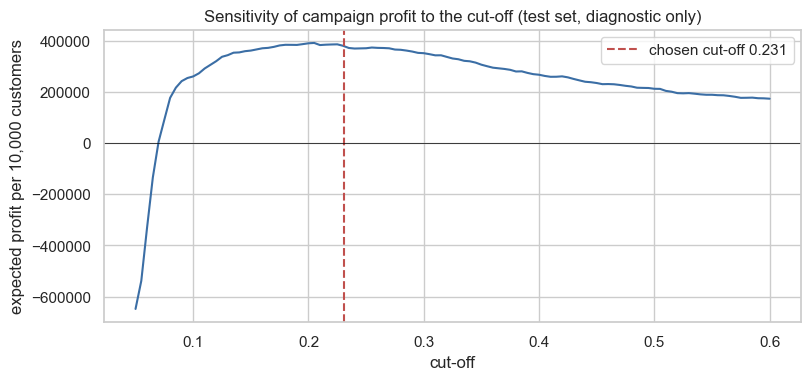

In [44]:
rng = np.random.default_rng(SEED)
N_BOOT = 2000
boot_profit = np.empty(N_BOOT)
for b in range(N_BOOT):
    idx = rng.integers(0, N_te, N_te)
    boot_profit[b] = profit_total(y_te[idx], p_te[idx], t_star) / N_te * LIST_SIZE

lo, hi = np.percentile(boot_profit, [2.5, 97.5])
print(f"Expected net profit per 10,000 customers: {net_profit:,.0f}  (95% bootstrap interval {lo:,.0f} to {hi:,.0f})")
print(f"Probability the campaign is profitable under this model: {(boot_profit > 0).mean():.1%}")

cutoffs = np.linspace(0.05, 0.6, 111)
profit_by_cutoff = np.array([profit_total(y_te, p_te, t) / N_te * LIST_SIZE for t in cutoffs])
plt.figure(figsize=(9, 3.8))
plt.plot(cutoffs, profit_by_cutoff, c=BLUE)
plt.axvline(t_star, c=RED, ls="--", label=f"chosen cut-off {t_star:.3f}")
plt.axhline(0, c="black", lw=0.5)
plt.xlabel("cut-off")
plt.ylabel("expected profit per 10,000 customers")
plt.title("Sensitivity of campaign profit to the cut-off (test set, diagnostic only)")
plt.legend()
plt.show()

- The campaign is profitable in essentially every bootstrap sample, but the **size** of the profit is uncertain (95% interval ≈ 330,000 to 428,000, about ± 50,000). Finance should plan on a range, not a point.
- Profit is **flat around the chosen cut-off** (not fragile to the exact threshold) and falls away quickly at higher cut-offs, where too many buyers are missed.
- **Main risks:** (i) the new list may have a different response rate than the development data (a purchased list of cold prospects may convert worse); (ii) economic conditions at campaign time, which the model leans on; (iii) the assumption that risk bands are independent of the model's picks. A pilot on a small random slice before full roll-out would tighten the estimate cheaply.

---

# Stage 6B (Extension): How much precision, recall and accuracy does the campaign need to make money?

Instead of judging a model by accuracy, precision or recall in isolation, **price** them using the Finance profit table.

### The maths (a list of `n` people, `π` = share who would buy)

- Buyers on the list: `π·n`. A model with recall `R` calls `TP = π·R·n` of them.
- A model with precision `P` must call `TP / P` people in total, so wasted calls are `FP = TP·(1/P − 1)`.
- **Profit** `= TP·V − FP·c`, with `V` = expected profit of a sale (1,001) and `c` = cost of a wasted call (300). Substituting: `Profit = π·R·n · [ V − c·(1/P − 1) ]`.
- **Accuracy** `= 1 − (FP + FN)/n`, with `FN = π·n − TP`.

**Three results follow**

1. **Break-even precision `P* = c / (V + c) = 300 / 1,301 = 23.06%`.** Below it every extra call destroys money, whatever the recall. This is the same number as the cut-off in 5.6.
2. **Above `P*`, profit is proportional to recall.** Recall is the volume lever; precision is the margin lever.
3. **Accuracy does not appear in the profit formula.** It counts a missed 1,001 sale and a wasted 300 call as the same error, so maximising accuracy is *not* maximising profit (shown below).

### Reusable functions

- `campaign_economics(precision, recall)`: money and accuracy implied by a given precision and recall.
- `required_precision(recall, target)` / `required_recall(precision, target)`: what the model must reach to hit a profit target.
- `balance_table(y, p)`: precision, recall, accuracy, F1 and profit at each cut-off of a scored sample.
- `breakeven_precision(V, c)`: precision below which calling should stop (re-run when Finance updates V or c).

In [45]:
def _resolve_defaults(prevalence, sale_value, call_cost):
    """Fill in defaults: test-set response rate, Finance-weighted sale value, cost per wasted call."""
    prevalence = y_te.mean() if prevalence is None else prevalence
    sale_value = TPV if sale_value is None else sale_value
    call_cost = -FPC if call_cost is None else call_cost
    return prevalence, sale_value, call_cost


def campaign_economics(precision, recall, prevalence=None, n=10_000, sale_value=None, call_cost=None):
    """Profit and classification metrics implied by a given precision and recall.

    precision, recall : operating point of the model (0-1)
    prevalence        : share of the list that would buy (default: test-set response rate)
    n                 : list size
    sale_value        : expected net profit of a sale (default: Finance-weighted 1,001)
    call_cost         : cost of a call that does not convert (default: 300)
    """
    prevalence, V, c = _resolve_defaults(prevalence, sale_value, call_cost)
    if not (0 < precision <= 1 and 0 <= recall <= 1):
        raise ValueError("precision must be in (0,1], recall in [0,1]")
    tp = prevalence * recall * n
    called = tp / precision
    fp = called - tp
    fn = prevalence * n - tp
    tn = n - tp - fp - fn
    if tn < 0:
        raise ValueError("this precision/recall pair is impossible for this prevalence (more calls than customers)")
    profit = tp * V - fp * c
    return dict(
        profit=profit, tp=tp, fp=fp, fn=fn, tn=tn, called=called, share_called=called / n,
        accuracy=(tp + tn) / n, profit_per_call=profit / called if called else np.nan,
        lost_fn=fn * V, wasted_fp=fp * c,
    )


def breakeven_precision(sale_value=None, call_cost=None):
    """Precision below which every extra call loses money."""
    _, V, c = _resolve_defaults(None, sale_value, call_cost)
    return c / (V + c)


def required_precision(recall, target_profit=0.0, prevalence=None, n=10_000, sale_value=None, call_cost=None):
    """Precision needed to earn `target_profit` at a given recall (nan if impossible even with 100% precision)."""
    prevalence, V, c = _resolve_defaults(prevalence, sale_value, call_cost)
    tp = prevalence * recall * n
    fp = (tp * V - target_profit) / c
    return np.nan if (tp <= 0 or fp < 0) else tp / (tp + fp)


def required_recall(precision, target_profit=0.0, prevalence=None, n=10_000, sale_value=None, call_cost=None):
    """Recall needed to earn `target_profit` at a given precision (nan if unreachable)."""
    prevalence, V, c = _resolve_defaults(prevalence, sale_value, call_cost)
    per_buyer = V - c * (1 / precision - 1)  # net profit contributed by each buyer we catch
    if per_buyer <= 0:
        return np.nan                        # below break-even precision: more recall only loses more
    recall = target_profit / (prevalence * n * per_buyer)
    return recall if recall <= 1 else np.nan


def balance_table(y, p, grid=None, **kwargs):
    """Precision, recall, accuracy, F1 and profit at each cut-off, using the model's own scores."""
    grid = np.linspace(0.02, 0.80, 157) if grid is None else grid
    rows = []
    for t in grid:
        tp_, fp_, fn_, _ = confusion_counts(y, p, t)
        if tp_ == 0:
            continue
        precision, recall = tp_ / (tp_ + fp_), tp_ / (tp_ + fn_)
        econ = campaign_economics(precision, recall, prevalence=y.mean(), **kwargs)
        rows.append(dict(
            cutoff=t, precision=precision, recall=recall, accuracy=econ["accuracy"],
            f1=2 * precision * recall / (precision + recall), profit=econ["profit"],
        ))
    return pd.DataFrame(rows)


# Sanity check: reproduce Stage 6 exactly from the test set's precision and recall
check = campaign_economics(tp / (tp + fp), tp / (tp + fn), prevalence=y_te.mean())
print(f"Function reproduces Stage 6: profit = {check['profit']:,.0f} (Stage 6: {net_profit:,.0f}) "
      f"| accuracy = {check['accuracy']:.3f} | called = {check['called']:,.0f}")
print(f"Break-even precision: {breakeven_precision():.4f}")

Function reproduces Stage 6: profit = 379,362 (Stage 6: 379,362) | accuracy = 0.877 | called = 1,280
Break-even precision: 0.2306


### (1) What must precision be for a given recall?

For each recall level: the precision needed to break even, and to earn the profit our model achieved (≈ 379k per 10,000).

In [46]:
recalls = [0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]
precision_needed = pd.DataFrame({
    "recall": recalls,
    "precision to break even (profit = 0)": [required_precision(r, 0) for r in recalls],
    f"precision to earn {net_profit:,.0f}": [required_precision(r, net_profit) for r in recalls],
    "precision to earn 600,000": [required_precision(r, 600_000) for r in recalls],
}).set_index("recall")
display(precision_needed.round(3))
print(f"Our model: precision {tp / (tp + fp):.3f}, recall {tp / (tp + fn):.3f} → profit {check['profit']:,.0f}")

,precision to break even (profit = 0),"precision to earn 379,362","precision to earn 600,000"
recall,,,
0.2,0.231,NaN,NaN
0.3,0.231,NaN,NaN
0.4,0.231,0.657,NaN
0.5,0.231,0.480,NaN
0.6,0.231,0.406,0.731
0.8,0.231,0.341,0.474
1.0,0.231,0.311,0.391


Our model: precision 0.458, recall 0.522 → profit 379,362


Break-even precision is **0.231 at every recall**; the profit targets are what create the trade-off. To earn 379k you need recall of at least ~34% even with perfect precision (`NaN` below that); at 40% recall precision must be 0.66, at 50% it must be 0.48 (our model: 0.46 precision at 0.52 recall), and at 80% recall 0.34 is enough. Low recall must be paid for with high precision, and vice versa.

### (2) What must recall be for a given precision?

In [47]:
precisions = [0.25, 0.30, 0.40, 0.46, 0.60, 0.80]
recall_needed = pd.DataFrame({
    "precision": precisions,
    "profit per buyer caught": [TPV + FPC * (1 / p_ - 1) for p_ in precisions],
    "recall needed for 200k": [required_recall(p_, 200_000) for p_ in precisions],
    "recall needed for 379k": [required_recall(p_, net_profit) for p_ in precisions],
    "profit at recall 0.5": [campaign_economics(p_, 0.5)["profit"] for p_ in precisions],
}).set_index("precision")
display(recall_needed.round(3))

,profit per buyer caught,recall needed for 200k,recall needed for 379k,profit at recall 0.5
precision,,,,
0.25,101.000,NaN,NaN,56720.492
0.30,301.000,0.592,NaN,169038.297
0.40,551.000,0.323,0.613,309435.553
0.46,648.826,0.274,0.521,364373.610
0.60,801.000,0.222,0.422,449832.809
0.80,926.000,0.192,0.365,520031.438


### (3) The whole balance on one chart

Each iso-profit curve is a set of precision/recall combinations earning exactly the same profit. The blue line is what our model delivers as the cut-off moves (computed from **out-of-fold training predictions**, so no test data is used to choose anything). The best operating point is where it touches the highest iso-profit curve.

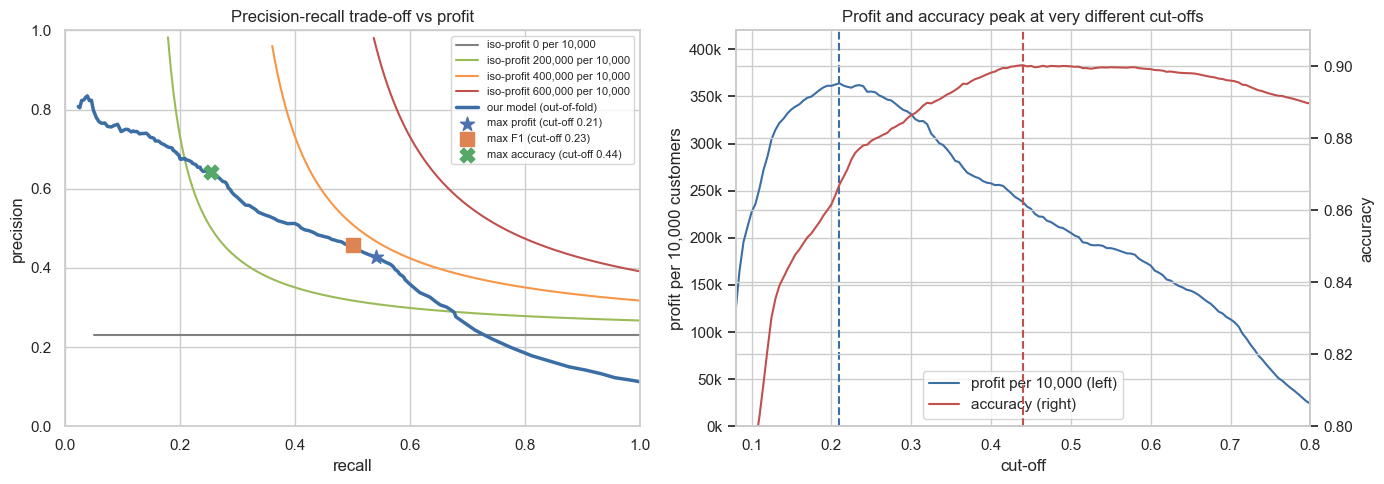

,cutoff,precision,recall,accuracy,f1,profit
maximise profit,0.210,0.427,0.541,0.867,0.478,363909.848
maximise F1,0.235,0.457,0.500,0.877,0.478,361985.955
maximise accuracy,0.440,0.642,0.254,0.900,0.364,237914.013


In [48]:
bt = balance_table(y_tr, oof)  # out-of-fold, training data only
best_profit = bt.loc[bt.profit.idxmax()]
best_f1 = bt.loc[bt.f1.idxmax()]
best_acc = bt.loc[bt.accuracy.idxmax()]

fig, (ax_pr, ax_cut) = plt.subplots(1, 2, figsize=(14, 5))

# Left: iso-profit curves vs the model's own precision-recall trade-off
recall_grid = np.linspace(0.05, 1.0, 200)
for target, colour in [(0, GREY), (200_000, GREEN), (400_000, ORANGE), (600_000, RED)]:
    precision_curve = [required_precision(r, target, prevalence=y_tr.mean()) for r in recall_grid]
    ax_pr.plot(recall_grid, precision_curve, c=colour, label=f"iso-profit {target:,.0f} per 10,000")
ax_pr.plot(bt.recall, bt.precision, c=BLUE, lw=2.5, label="our model (out-of-fold)")
for label, row, marker in [("max profit", best_profit, "*"), ("max F1", best_f1, "s"), ("max accuracy", best_acc, "X")]:
    ax_pr.scatter(row.recall, row.precision, s=110, marker=marker, zorder=5, label=f"{label} (cut-off {row.cutoff:.2f})")
ax_pr.set_xlim(0, 1)
ax_pr.set_ylim(0, 1)
ax_pr.set_xlabel("recall")
ax_pr.set_ylabel("precision")
ax_pr.set_title("Precision-recall trade-off vs profit")
ax_pr.legend(fontsize=8, loc="upper right")

# Right: profit and accuracy peak at very different cut-offs
ax_cut.plot(bt.cutoff, bt.profit, c=BLUE, label="profit per 10,000 (left)")
ax_cut.set_xlabel("cut-off")
ax_cut.set_ylabel("profit per 10,000 customers")
ax_cut.set_xlim(0.08, 0.8)
ax_cut.set_ylim(0, 420_000)
ax_cut.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}k"))
ax_acc = ax_cut.twinx()
ax_acc.plot(bt.cutoff, bt.accuracy, c=RED, label="accuracy (right)")
ax_acc.set_ylabel("accuracy")
ax_acc.set_ylim(0.80, 0.91)
ax_cut.axvline(best_profit.cutoff, c=BLUE, ls="--")
ax_acc.axvline(best_acc.cutoff, c=RED, ls="--")
ax_cut.set_title("Profit and accuracy peak at very different cut-offs")
handles = ax_cut.get_legend_handles_labels()[0] + ax_acc.get_legend_handles_labels()[0]
labels = ax_cut.get_legend_handles_labels()[1] + ax_acc.get_legend_handles_labels()[1]
ax_cut.legend(handles, labels, loc="lower center")

plt.tight_layout()
plt.show()

best_points = pd.DataFrame([best_profit, best_f1, best_acc], index=["maximise profit", "maximise F1", "maximise accuracy"])
display(best_points[["cutoff", "precision", "recall", "accuracy", "f1", "profit"]].round(3))

**What this tells us**

- **Maximising accuracy** picks a high cut-off (≈ 0.44): high precision (0.64) but low recall (0.25), earning about **238k, roughly a third less** than the profit-optimal point (≈ 364k per 10,000). It is the wrong yardstick because it treats a missed 1,001 sale and a wasted 300 call as equal mistakes.
- **Maximising profit** lands at cut-off ≈ 0.21: **precision ≈ 0.43, recall ≈ 54%**, comfortably above the 23% break-even. Its accuracy (≈ 0.867) is lower than the accuracy-maximising point (0.90), which is correct behaviour, not a flaw.
- **Maximising F1** (cut-off ≈ 0.235) lands close to the profit optimum here (≈ 362k vs ≈ 364k per 10,000). That is partly luck of the 1,001 / 300 ratio: F1 weights precision and recall equally, so with more lopsided economics it would drift away from the profit-optimal point. Do not rely on it as a shortcut.
- **Rule of thumb:** keep precision above ≈ 23% (otherwise stop dialling), then push recall as high as that allows. At precision P, one extra point of recall is worth about `π·n·[V − c·(1/P − 1)] / 100`; at P = 0.46 that is ≈ 11.2 buyers × 649 ≈ **7,300 per 10,000 customers**.

### What-if: how break-even moves when the economics move

Cheaper calls or richer sales make the campaign more forgiving. Break-even precision is the quickest read.

,sale value 500,sale value 750,sale value 1001,sale value 1250,sale value 1500
call cost 150,0.231,0.167,0.130,0.107,0.091
call cost 200,0.286,0.211,0.167,0.138,0.118
call cost 300,0.375,0.286,0.231,0.194,0.167
call cost 400,0.444,0.348,0.286,0.242,0.211
call cost 500,0.500,0.400,0.333,0.286,0.250


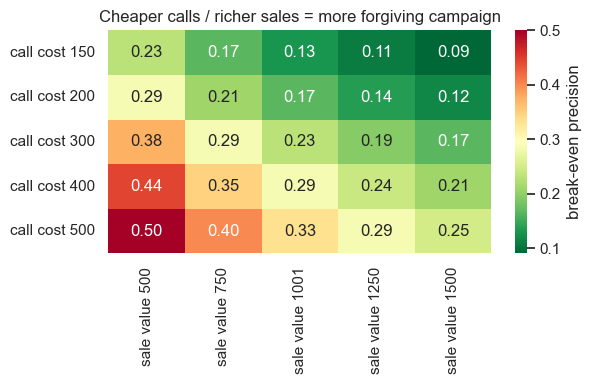

In [49]:
call_costs = [150, 200, 300, 400, 500]
sale_values = [500, 750, 1001, 1250, 1500]
what_if = pd.DataFrame(
    [[breakeven_precision(v, c) for v in sale_values] for c in call_costs],
    index=[f"call cost {c}" for c in call_costs],
    columns=[f"sale value {v}" for v in sale_values],
)
display(what_if.round(3))

plt.figure(figsize=(6.2, 4))
sns.heatmap(what_if, annot=True, fmt=".2f", cmap="RdYlGn_r", cbar_kws={"label": "break-even precision"})
plt.title("Cheaper calls / richer sales = more forgiving campaign")
plt.tight_layout()
plt.show()

---

# Stage 7: Summary, answers to the case questions, and limitations

### 7.1 Summary

A regularised logistic-regression response model was built on the **14 inputs available *before* a call** (call duration is excluded as leakage). It ranks customers with **test AUC ≈ 0.80 (Gini ≈ 0.60, KS ≈ 0.50)** and is well calibrated. Calling only customers whose predicted probability exceeds the **break-even 23%** captures about **half of all buyers by calling ≈ 13% of the list**, a lift of ≈ 4×. On a 10,000-record list it yields an **expected net profit of ≈ 380,000** (calling everyone would lose ≈ 1.5 million), with ≈ 745,000 of potential profit lost to misclassification, most of it missed buyers.

### 7.2 The case study's questions, answered

| # | Question | Where | Short answer |
| --- | --- | --- | --- |
| 1 | Are all inputs relevant? | 1, 2, 3.1 | No. Call duration is leakage; home loan, personal loan and weekday are noise (IV ≈ 0). |
| 2 | What does the data look like; outliers/corrections? | 1 | Clean (no missing). Fixes: 11 duplicates, 999 code → flag, call attempts capped at 10, rare levels pooled. |
| 3 | Discriminating power? | 2 | Information Value + univariate AUC, computed on train only. |
| 4 | Control high correlations? | 2, 3.6 | Correlation matrix + VIF; keep one of the three near-identical macro variables (VIFs 32-64 → about 3). |
| 5 | Do class imbalances matter? | 3.5 | For metrics and the cut-off, yes; for training, no resampling (it would distort probabilities). Stratified splits + AUC/PR-AUC/profit. |
| 6 | Different scales? | 3.4 | Standardise for logistic regression (regularisation); trees don't care. |
| 7 | Encode / group categoricals? | 3.2 | One-hot (nominal data); levels < 1% pooled, learned on train. |
| 8 | Bin numerics? | 3.3 | No: +0.0004 AUC, not worth the complexity. |
| 9 | Split for train/test? | 2.1, 3.8 | Yes: stratified 70/30 *before* any target-aware step; test set scored once. |
| 10 | Validate while training? | 3-5 | 5-fold stratified CV; preprocessing re-fit inside each fold. |
| 11 | Which model is best? | 4.2, 5.1-5.2 | Pre-agreed criteria + 1-SE rule: simplest model within noise of the best, i.e. logistic regression. |
| 12 | Over/under-fit? | 4.3-4.4, 5.4 | Train-vs-validation gaps, depth curve, learning curve, hold-out test, calibration. |
| 13 | Variable importance? | 5.9 | Permutation importance + odds ratios; employment variation rate (macro) dominates. |
| 14 | Fit different models; which to optimise? | 4, 5.1 | Logistic, tree, forest, boosting; equal tuning effort; chosen by rule. |
| 15 | How optimise, and why? | 5.3 | Grid over penalty × C, AUC scoring, stratified CV: regularisation controls bias-variance. |
| 16 | Cut-off? | 5.6 | Break-even from the profit table = 0.2306, confirmed on out-of-fold data. |
| 17 | Confusion matrix? | 5.8 | TP/FP/FN/TN in business terms; why accuracy is the wrong yardstick. |
| Bonus | Profit and lost opportunity | 6 | ≈ 380k net profit; ≈ 745k lost to misclassification (≈ 537k missed buyers + ≈ 208k wasted calls). |
| Extension | What precision/recall/accuracy does profit require? | 6B | Break-even precision 23.1% at any recall; profit-optimal point ≈ 0.43 precision / ≈ 54% recall; accuracy-max earns ~⅓ less. |

### 7.3 Limitations & next steps

1. **Macro variables act as a calendar.** The strongest driver is the economic cycle: excellent in-sample, but lift may shrink if conditions on the new list differ. Tested in 5.10: holding out whole macro periods does not lower AUC (0.789 vs 0.784 on random folds), and a model without the macro variables still earns about 293,000 per 10,000 customers at the same cut-off. A true out-of-time test still needs call dates, plus score-distribution monitoring (PSI) after launch.
2. **Random, not time-based, split.** If rows span different quarters, a random split slightly flatters the model; a time-based hold-out would be more honest for deployment.
3. **Prevalence on the new list.** A purchased prospect list probably converts differently from the development sample. Recalibrate or run a small pilot before committing the full budget.
4. **Masked categories.** Labels are anonymised (e.g. `Cat_3_h***l`), so which levels matter can be said but not interpreted in plain language.
5. **Profit inputs are given, not estimated.** The 1,001 expected sale value rests on the Finance table and risk-band mix; the cut-off moves if either changes (`t* = 300 / (sale value + 300)`).
6. **`calls` (attempts)** includes the current call; a stricter "attempts *before* today" feature would be safer in production, and the model loses almost nothing without it.
7. **Deployment model** would be refit on train + test (all labelled data) with the same hyper-parameters; the test metrics here are for the model fit on the 70% only.